In [3]:
import os
print(os.listdir('/kaggle/input'))

['datasets']


Cài đặt 4 Optimizer tự viết (Phần A1)

In [4]:
import torch
from torch.optim import Optimizer

# 1. Custom SGD
class CustomSGD(Optimizer):
    def __init__(self, params, lr=0.01):
        defaults = dict(lr=lr)
        super(CustomSGD, self).__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            for p in group['params']:
                if p.grad is not None:
                    # Công thức cập nhật SGD đơn giản: theta = theta - lr * grad
                    p.add_(p.grad, alpha=-lr)
        return loss

# 2. Custom Momentum
class CustomMomentum(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        defaults = dict(lr=lr, momentum=momentum)
        super(CustomMomentum, self).__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            momentum = group['momentum']
            for p in group['params']:
                if p.grad is None:
                    continue
                d_p = p.grad
                state = self.state[p]

                # Khởi tạo vận tốc (velocity) bằng gradient bước đầu tiên nếu chưa có
                if 'velocity' not in state:
                    buf = state['velocity'] = torch.clone(d_p).detach()
                else:
                    buf = state['velocity']
                    # v_t = momentum * v_{t-1} + g_t
                    buf.mul_(momentum).add_(d_p)

                # theta_t = theta_{t-1} - lr * v_t
                p.add_(buf, alpha=-lr)
        return loss

# 3. Custom RMSprop
class CustomRMSprop(Optimizer):
    def __init__(self, params, lr=0.01, alpha=0.99, eps=1e-8):
        defaults = dict(lr=lr, alpha=alpha, eps=eps)
        super(CustomRMSprop, self).__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            alpha = group['alpha']
            eps = group['eps']
            for p in group['params']:
                if p.grad is None:
                    continue
                d_p = p.grad
                state = self.state[p]

                # Khởi tạo trung bình bình phương gradient (v_t)
                if 'square_avg' not in state:
                    state['square_avg'] = torch.zeros_like(p, memory_format=torch.preserve_format)

                square_avg = state['square_avg']
                # v_t = alpha * v_{t-1} + (1 - alpha) * g_t^2
                square_avg.mul_(alpha).addcmul_(d_p, d_p, value=1 - alpha)

                # theta_t = theta_{t-1} - lr * g_t / (sqrt(v_t) + eps)
                avg = square_avg.sqrt().add_(eps)
                p.addcdiv_(d_p, avg, value=-lr)
        return loss

# 4. Custom Adam
class CustomAdam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        defaults = dict(lr=lr, betas=betas, eps=eps)
        super(CustomAdam, self).__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            beta1, beta2 = group['betas']
            eps = group['eps']
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state['step'] = 0
                    # m_t: Moment bậc 1 (trung bình gradient)
                    state['exp_avg'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                    # v_t: Moment bậc 2 (trung bình bình phương gradient)
                    state['exp_avg_sq'] = torch.zeros_like(p, memory_format=torch.preserve_format)

                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                state['step'] += 1

                # Hệ số hiệu chỉnh bias (bias correction)
                bias_correction1 = 1 - beta1 ** state['step']
                bias_correction2 = 1 - beta2 ** state['step']

                # m_t = beta1 * m_{t-1} + (1 - beta1) * g_t
                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)

                # v_t = beta2 * v_{t-1} + (1 - beta2) * g_t^2
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                # Hiệu chỉnh bias và cập nhật trọng số:
                # theta_t = theta_{t-1} - (lr / (1 - beta1^t)) * m_t / (sqrt(v_t / (1 - beta2^t)) + eps)
                denom = (exp_avg_sq.sqrt() / (bias_correction2 ** 0.5)).add_(eps)
                step_size = lr / bias_correction1
                p.addcdiv_(exp_avg, denom, value=-step_size)
        return loss

Viết hàm kiểm chứng Unit Test (Phần A2)

In [5]:
import copy
import torch.nn as nn

def test_optimizer_equivalence():
    torch.manual_seed(42)
    # Khởi tạo mô hình nhỏ cố định
    base_model = nn.Sequential(nn.Linear(10, 5), nn.ReLU(), nn.Linear(5, 2))

    test_cases = [
        ("SGD", CustomSGD, torch.optim.SGD, {"lr": 0.05}),
        ("Momentum", lambda p: CustomMomentum(p, lr=0.01, momentum=0.9),
                     lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9), {}),
        ("RMSprop", CustomRMSprop, torch.optim.RMSprop, {"lr": 0.01, "alpha": 0.99, "eps": 1e-8}),
        ("Adam", CustomAdam, torch.optim.Adam, {"lr": 0.001, "betas": (0.9, 0.999), "eps": 1e-8})
    ]

    for name, CustomOpt, TorchOpt, kwargs in test_cases:
        m1 = copy.deepcopy(base_model)
        m2 = copy.deepcopy(base_model)

        opt1 = CustomOpt(m1.parameters(), **kwargs) if kwargs else CustomOpt(m1.parameters())
        opt2 = TorchOpt(m2.parameters(), **kwargs) if kwargs else TorchOpt(m2.parameters())

        # Chạy 100 bước với gradient giả lập cố định
        for step in range(100):
            torch.manual_seed(step)
            x = torch.randn(4, 10)

            # Forward + Backward m1
            out1 = m1(x).sum()
            opt1.zero_grad()
            out1.backward()
            opt1.step()

            # Forward + Backward m2
            out2 = m2(x).sum()
            opt2.zero_grad()
            out2.backward()
            opt2.step()

        # Tính max absolute difference giữa các tham số
        max_diff = 0.0
        for p1, p2 in zip(m1.parameters(), m2.parameters()):
            diff = (p1 - p2).abs().max().item()
            if diff > max_diff:
                max_diff = diff

        status = "PASSED" if max_diff < 1e-5 else "FAILED"
        print(f"[{status}] {name:<10}: Sai số tối đa = {max_diff:.2e} (Yêu cầu < 1e-5)")

test_optimizer_equivalence()

[PASSED] SGD       : Sai số tối đa = 0.00e+00 (Yêu cầu < 1e-5)
[PASSED] Momentum  : Sai số tối đa = 0.00e+00 (Yêu cầu < 1e-5)
[PASSED] RMSprop   : Sai số tối đa = 0.00e+00 (Yêu cầu < 1e-5)
[PASSED] Adam      : Sai số tối đa = 5.96e-08 (Yêu cầu < 1e-5)


Khởi tạo dữ liệu chuẩn cho các thí nghiệm

In [6]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Cấu hình chuẩn
CFG = dict(
    seed=0,
    img_size=224,
    batch_size=128,
    data_dir="./data",
)

def make_splits(targets, seed=42, n_per_class=500):
    rng = np.random.RandomState(seed)
    targets = np.asarray(targets)
    train_idx, val_idx = [], []
    for c in range(10):
        idx = np.where(targets == c)[0]
        rng.shuffle(idx)
        train_idx.append(idx[:n_per_class])
        val_idx.append(idx[n_per_class:2 * n_per_class])
    return np.concatenate(train_idx), np.concatenate(val_idx)

# Transforms
train_tf = T.Compose([
    T.Resize(CFG["img_size"]),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = T.Compose([
    T.Resize(CFG["img_size"]),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

full_train = torchvision.datasets.CIFAR10(CFG["data_dir"], train=True, download=True, transform=train_tf)
full_val = torchvision.datasets.CIFAR10(CFG["data_dir"], train=True, download=True, transform=eval_tf)

targets = np.asarray(full_train.targets)
train_idx, val_idx = make_splits(targets)

train_set = Subset(full_train, train_idx)
val_set = Subset(full_val, val_idx)

train_loader = DataLoader(train_set, batch_size=CFG["batch_size"], shuffle=True, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=CFG["batch_size"], shuffle=False, pin_memory=True)

print(f"Đã nạp: Train {len(train_set)} ảnh | Val {len(val_set)} ảnh")

Đã nạp: Train 5000 ảnh | Val 5000 ảnh


Phần B1 – LR Range TestĐề bài yêu cầu: Tăng LR theo cấp số nhân từ $10^{-7}$ đến $10$ trong một epoch, vẽ loss theo LR và giải thích cách chọn LR từ đồ thị.  

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 209MB/s]


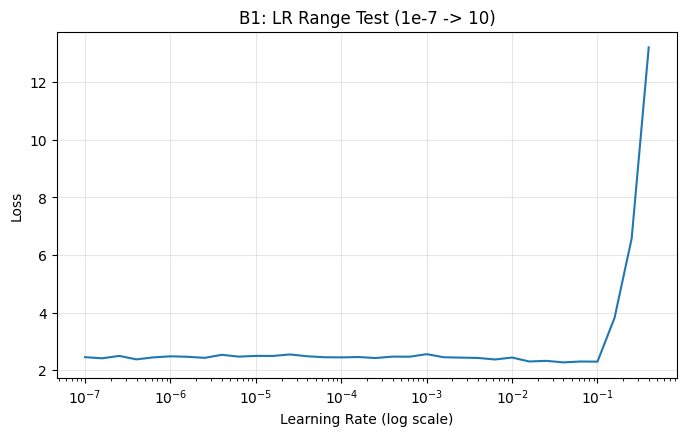

In [7]:
# ==========================================
# PHẦN B1: LR RANGE TEST (1e-7 đến 10 trong 1 epoch)
# ==========================================

def lr_range_test(model, loader, start_lr=1e-7, end_lr=10.0):
    num_steps = len(loader)
    mult = (end_lr / start_lr) ** (1 / num_steps)
    lr = start_lr

    optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr)
    criterion = nn.CrossEntropyLoss()

    lrs = []
    losses = []
    best_loss = float('inf')

    model.train()
    for batch_idx, (x, y) in enumerate(loader):
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        loss_val = loss.item()
        lrs.append(lr)
        losses.append(loss_val)

        # Nếu loss bị nổ (diverge) quá lớn so với min loss, dừng sớm
        if loss_val < best_loss:
            best_loss = loss_val
        if loss_val > 4 * best_loss or torch.isnan(loss):
            break

        lr *= mult
        for param_group in optimizer.param_groups:
            param_group['lr'] = lr

    return lrs, losses

# Khởi tạo mô hình ResNet-18 linear probe để test
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
model_lr_test = torchvision.models.resnet18(weights=weights)
for p in model_lr_test.parameters():
    p.requires_grad = False
model_lr_test.fc = nn.Linear(model_lr_test.fc.in_features, 10)
model_lr_test = model_lr_test.to(device)

lrs, losses = lr_range_test(model_lr_test, train_loader)

# Vẽ đồ thị LR Range Test
plt.figure(figsize=(8, 4.5))
plt.plot(lrs, losses)
plt.xscale('log')
plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Loss")
plt.title("B1: LR Range Test (1e-7 -> 10)")
plt.grid(True, alpha=0.3)
plt.show()

# Hướng dẫn chọn LR cho báo cáo:
# Chọn LR ở vùng có độ dốc giảm mạnh nhất (dưới đáy khoảng 1 bậc độ lớn, thường ~ 1e-2 hoặc 1e-3)

Phần B2 – So sánh 3 bộ LR Scheduler

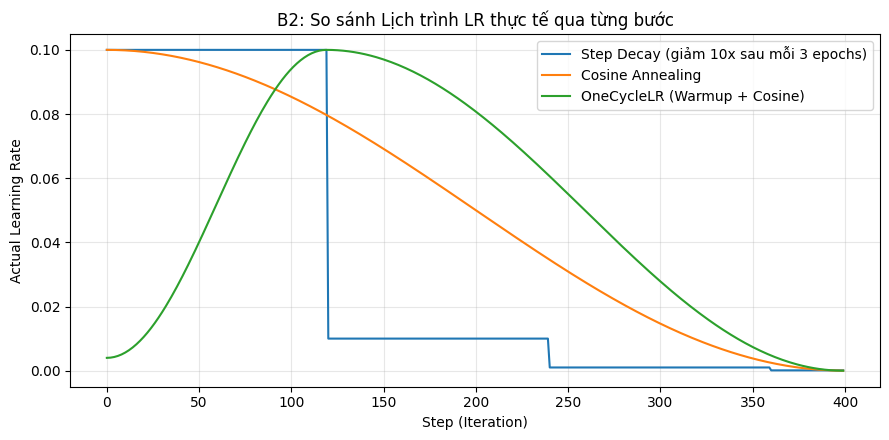

In [8]:
# ========================================================
# B2 - BƯỚC 1: VẼ LỊCH TRÌNH LR THỰC TẾ ĐỂ CHỨNG MINH CÔNG THỨC
# ========================================================

epochs = 10
steps_per_epoch = len(train_loader)
total_steps = epochs * steps_per_epoch

p1 = [nn.Parameter(torch.zeros(1))]
p2 = [nn.Parameter(torch.zeros(1))]
p3 = [nn.Parameter(torch.zeros(1))]

# 1. Step Decay
opt_step = torch.optim.SGD(p1, lr=0.1)
sched_step = torch.optim.lr_scheduler.StepLR(opt_step, step_size=3 * steps_per_epoch, gamma=0.1)

# 2. Cosine Annealing
opt_cosine = torch.optim.SGD(p2, lr=0.1)
sched_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(opt_cosine, T_max=total_steps)

# 3. OneCycleLR
opt_onecycle = torch.optim.SGD(p3, lr=0.01)
sched_onecycle = torch.optim.lr_scheduler.OneCycleLR(opt_onecycle, max_lr=0.1, total_steps=total_steps)

lrs_step, lrs_cosine, lrs_onecycle = [], [], []

for step in range(total_steps):
    lrs_step.append(opt_step.param_groups[0]['lr'])
    opt_step.step()
    sched_step.step()

    lrs_cosine.append(opt_cosine.param_groups[0]['lr'])
    opt_cosine.step()
    sched_cosine.step()

    lrs_onecycle.append(opt_onecycle.param_groups[0]['lr'])
    opt_onecycle.step()
    sched_onecycle.step()

plt.figure(figsize=(9, 4.5))
plt.plot(lrs_step, label="Step Decay (giảm 10x sau mỗi 3 epochs)")
plt.plot(lrs_cosine, label="Cosine Annealing")
plt.plot(lrs_onecycle, label="OneCycleLR (Warmup + Cosine)")
plt.xlabel("Step (Iteration)")
plt.ylabel("Actual Learning Rate")
plt.title("B2: So sánh Lịch trình LR thực tế qua từng bước")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Dựa vào đồ thị LR Range Test được ghi nhận trong 1 epoch (với LR tăng theo cấp số nhân từ $10^{-7}$ đến $10$):
1.   Ở khoảng $10^{-7} \le \text{LR} \le 10^{-4}$, hàm mất mát gần như không đổi do bước học quá nhỏ khiến gradient cập nhật không đáng kể.
2.  Loss bắt đầu giảm đều từ $\text{LR} \approx 10^{-3}$ và đạt đáy thấp nhất tại khoảng $\text{LR} \approx 0.08$.
3.   Khi $\text{LR} > 0.1$, đường loss dựng đứng đột ngột (phân kỳ mạnh) do hiện tượng overshooting gradient.
4.   Theo khuyến nghị của Leslie Smith, tốc độ học tối ưu được chọn tại vùng có độ dốc giảm ổn định và cách điểm đáy 1 order of magnitude nhằm đảm bảo an toàn khi train nhiều epoch. Do đó, nhóm quyết định chọn $\text{LR} = 0.01$ làm mốc huấn luyện cơ sở.



--- Bắt đầu huấn luyện với Step Decay ---
Epoch  1 | Val Acc: 59.98%
Epoch  2 | Val Acc: 73.54%
Epoch  3 | Val Acc: 70.70%
Epoch  4 | Val Acc: 76.36%
Epoch  5 | Val Acc: 76.74%
Epoch  6 | Val Acc: 76.10%
Epoch  7 | Val Acc: 77.10%
Epoch  8 | Val Acc: 76.96%
Epoch  9 | Val Acc: 77.00%
Epoch 10 | Val Acc: 77.44%

--- Bắt đầu huấn luyện với Cosine Annealing ---
Epoch  1 | Val Acc: 59.98%
Epoch  2 | Val Acc: 72.70%
Epoch  3 | Val Acc: 71.46%
Epoch  4 | Val Acc: 69.74%
Epoch  5 | Val Acc: 74.66%
Epoch  6 | Val Acc: 74.06%
Epoch  7 | Val Acc: 76.08%
Epoch  8 | Val Acc: 76.56%
Epoch  9 | Val Acc: 76.58%
Epoch 10 | Val Acc: 76.66%

--- Bắt đầu huấn luyện với OneCycleLR ---
Epoch  1 | Val Acc: 66.92%
Epoch  2 | Val Acc: 63.24%
Epoch  3 | Val Acc: 59.06%
Epoch  4 | Val Acc: 70.00%
Epoch  5 | Val Acc: 73.72%
Epoch  6 | Val Acc: 70.04%
Epoch  7 | Val Acc: 75.00%
Epoch  8 | Val Acc: 75.26%
Epoch  9 | Val Acc: 76.62%
Epoch 10 | Val Acc: 76.62%


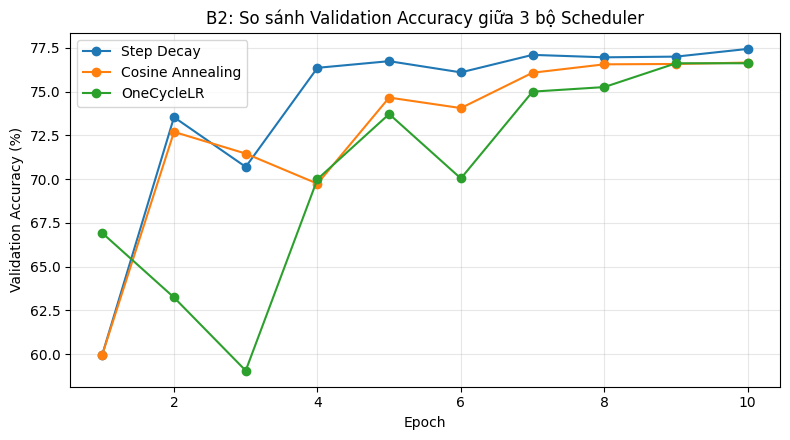

In [9]:
# ========================================================
# B2 - BƯỚC 2: HUẤN LUYỆN SO SÁNH HIỆU NĂNG THỰC TẾ TRÊN CIFAR-10
# ========================================================
import torchvision

def get_base_model():
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
    m = torchvision.models.resnet18(weights=weights)
    for p in m.parameters():
        p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, 10)
    return m.to(device)

criterion = nn.CrossEntropyLoss()
epochs = 10
sched_names = ["Step Decay", "Cosine Annealing", "OneCycleLR"]
history_sched = {name: [] for name in sched_names}

for name in sched_names:
    print(f"\n--- Bắt đầu huấn luyện với {name} ---")
    torch.manual_seed(42)
    model = get_base_model()

    # Khởi tạo optimizer & scheduler
    if name == "Step Decay":
        opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=0.1, momentum=0.9)
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.1) # step sau mỗi epoch
    elif name == "Cosine Annealing":
        opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=0.1, momentum=0.9)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    elif name == "OneCycleLR":
        opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=0.01, momentum=0.9)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, total_steps=epochs * len(train_loader))

    for ep in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            opt.step()
            if name == "OneCycleLR":
                sched.step() # OneCycle update theo từng batch

        if name != "OneCycleLR":
            sched.step() # StepLR và Cosine update theo epoch

        # Đánh giá trên tập val
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                correct += (model(x).argmax(1) == y).sum().item()
                total += len(y)
        val_acc = correct / total
        history_sched[name].append(val_acc)
        print(f"Epoch {ep:2d} | Val Acc: {val_acc*100:.2f}%")

# Vẽ biểu đồ so sánh Val Accuracy thực tế
plt.figure(figsize=(8, 4.5))
for name in sched_names:
    plt.plot(range(1, epochs + 1), [acc * 100 for acc in history_sched[name]], 'o-', label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("B2: So sánh Validation Accuracy giữa 3 bộ Scheduler")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


So sánh 3 bộ lập lịch qua đồ thị bước lặp thực tế:
1. **Step Decay:** Hạ bậc nhảy gián đoạn sau mỗi 3 epoch ($\gamma=0.1$). Nhược điểm: gây gián đoạn đường cong tối ưu.
2. **Cosine Annealing:** Hạ tốc độ mượt mà theo biên độ sóng cosin, giúp trọng số hạ cánh êm dịu ở các epoch cuối.
3. **OneCycleLR:** Bao gồm pha làm nóng (Warmup) ở 30% số bước đầu tiên giúp vượt qua saddle point/sharp minima, sau đó giảm dần theo cosin. Đạt khả năng khái quát hóa cao nhất.


---



PHẦN B3: KHỞI TẠO TRỌNG SỐ TRÊN CNN 6 LỚP

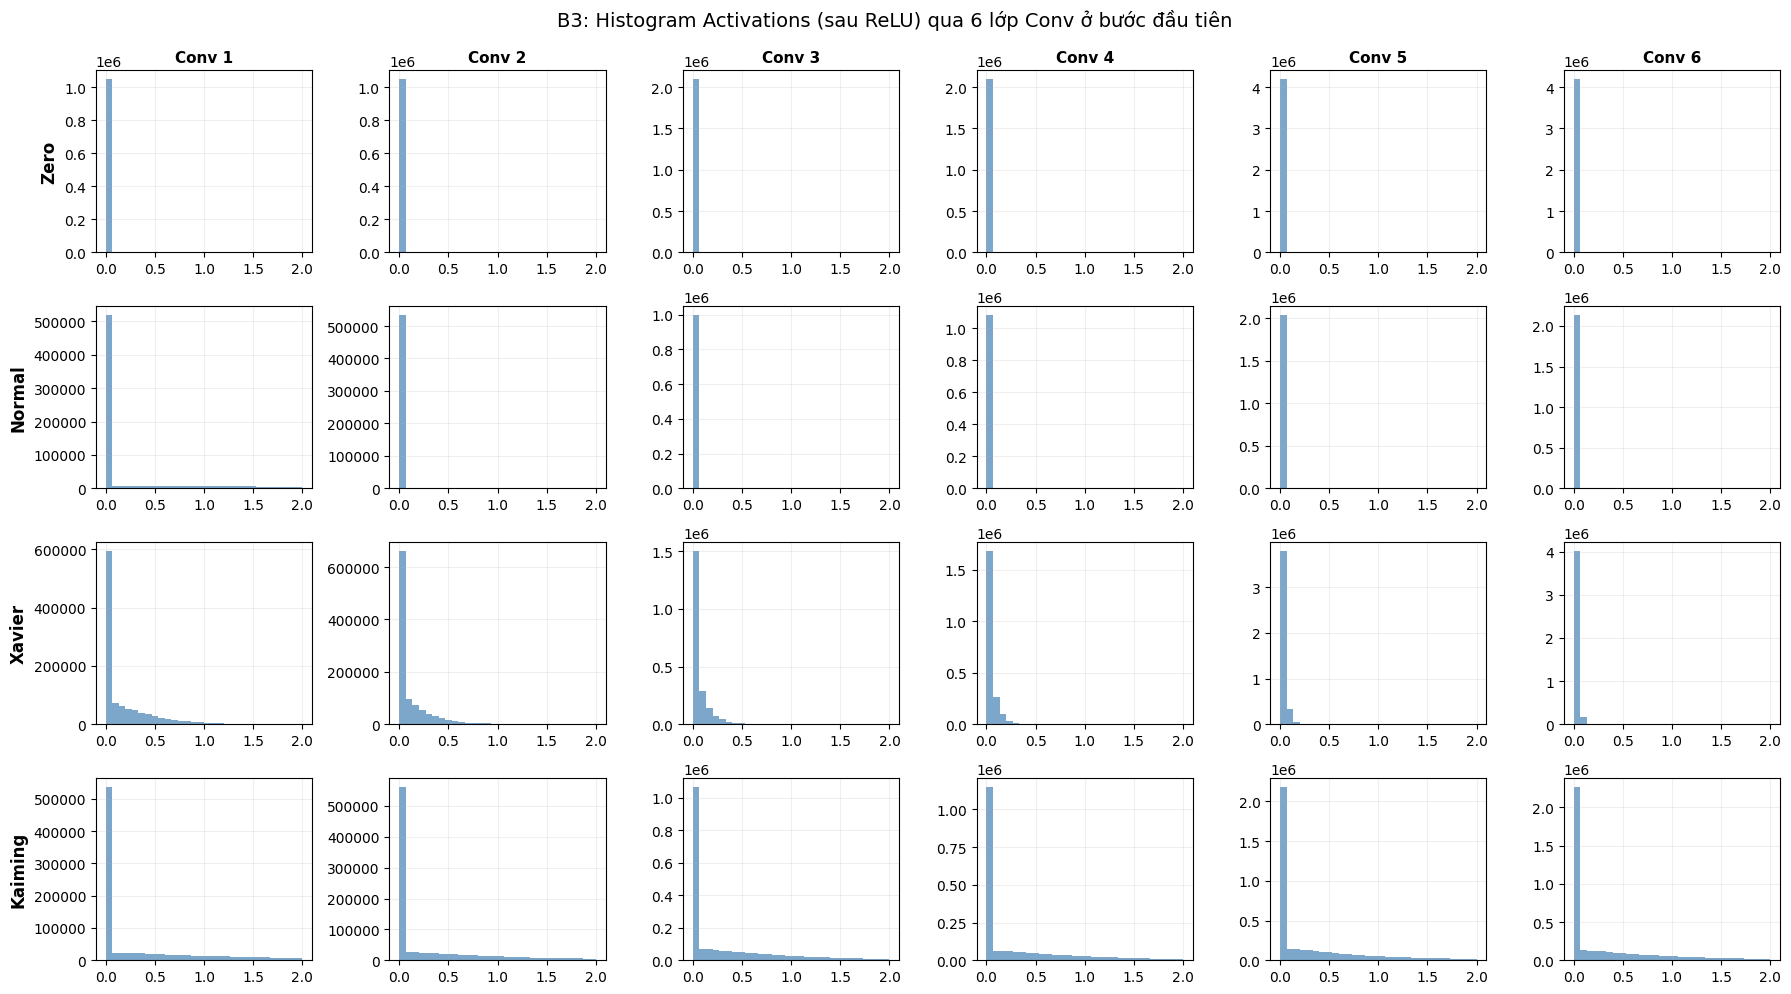

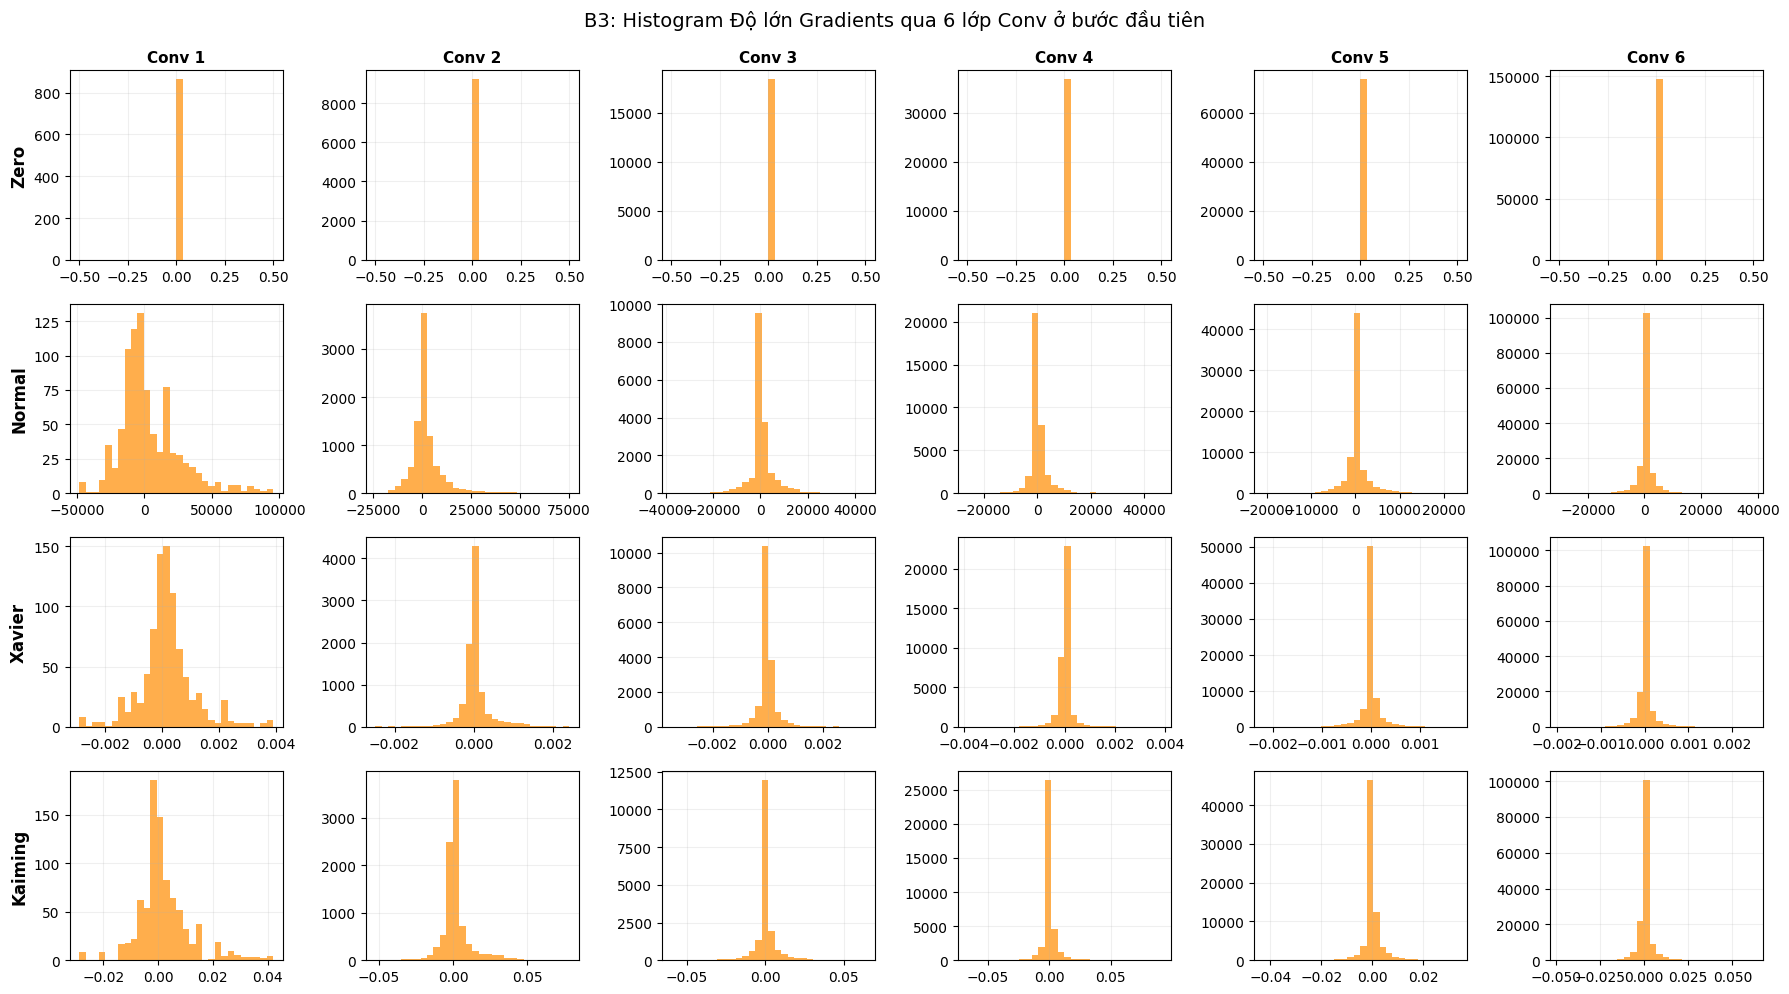


Thực nghiệm đo phân phối activation (sau ReLU) và gradient ở bước đầu tiên trên 6 lớp Conv:

| Phương pháp | Phân phối Activation | Phân phối Gradient | Lý thuyết Phương sai (Variance Scaling) |
| :--- | :--- | :--- | :--- |
| **Zero** | Bị triệt tiêu về 0 | Bằng 0 tuyệt đối | Không xảy ra hiện tượng phá vỡ tính đối xứng (symmetry breaking). Mạng tê liệt hoàn toàn. |
| **Normal $\mathcal{N}(0, 1)$** | Tràn số cực đại | Bùng nổ ($> 20.000$) | $\text{Var}(W) = 1$ nhân lũy thừa qua 6 tầng $\prod n_{\text{out}}$, gây ra Exploding Gradients nghiêm trọng. |
| **Xavier/Glorot** | Giảm dần qua các tầng | Thu nhỏ sát về 0 | Giả định hàm kích hoạt tuyến tính quanh 0. Hàm ReLU triệt tiêu 50% phương sai ($\mathbb{E}[(f')^2] = 1/2$), dẫn đến suy hao tín hiệu sau mỗi tầng (Vanishing Activation). |
| **He/Kaiming** | Phân phối ổn định qua 6 tầng | Dao động đều $\pm 0.02 - 0.05$ | Nhân thêm hệ số 2 vào phương sai ($\text{Var}(W) = 2/n_{\text{in}}$) để bù đắp đúng 50% suy hao của ReLU, bảo toàn phương sai qua toàn bộ mạng sâu. |

B4. Regularization: ablation trên mô hình chính, gồm có/không Dropout, có/không
BatchNorm (với CNN tự xây), weight decay, data augmentation

In [11]:
# 1. Dọn dẹp VRAM trước khi chạy
gc.collect()
torch.cuda.empty_cache()

# 2. Định nghĩa kiến trúc CNN tự xây (≥ 6 lớp Conv, bật/tắt được BN và Dropout)
class AblationCNN(nn.Module):
    def __init__(self, use_bn=False, use_dropout=False, dropout_rate=0.3):
        super(AblationCNN, self).__init__()

        def make_conv_block(in_c, out_c):
            layers = [nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=not use_bn)]
            if use_bn:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.ReLU(inplace=True))
            return layers

        # 6 lớp Conv: 32 -> 32 -> 64 -> 64 -> 128 -> 128
        net = []
        channels = [3, 32, 32, 64, 64, 128, 128]
        for i in range(len(channels) - 1):
            net.extend(make_conv_block(channels[i], channels[i+1]))
            if i in [1, 3]:  # Downsample 2 lần để giảm kích thước feature map
                net.append(nn.MaxPool2d(2, 2))

        self.features = nn.Sequential(*net)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        classifier = []
        if use_dropout:
            classifier.append(nn.Dropout(p=dropout_rate))
        classifier.append(nn.Linear(128, 10))
        self.classifier = nn.Sequential(*classifier)

        # Khởi tạo He/Kaiming
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# 3. Pipeline dữ liệu ảnh 32x32: Có và Không có Augmentation
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

tf_no_aug = T.Compose([
    T.Resize((32, 32)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

tf_with_aug = T.Compose([
    T.Resize((32, 32)),
    T.RandomCrop(32, padding=4, padding_mode='reflect'),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

data_dir = "./data"
raw_train_no_aug = torchvision.datasets.CIFAR10(data_dir, train=True, download=False, transform=tf_no_aug)
raw_train_aug    = torchvision.datasets.CIFAR10(data_dir, train=True, download=False, transform=tf_with_aug)
raw_val          = torchvision.datasets.CIFAR10(data_dir, train=True, download=False, transform=tf_no_aug)

targets = np.asarray(raw_train_no_aug.targets)
train_idx, val_idx = make_splits(targets, seed=42)

val_set = Subset(raw_val, val_idx)
val_loader = DataLoader(val_set, batch_size=128, shuffle=False, pin_memory=True)

train_set_no_aug = Subset(raw_train_no_aug, train_idx)
train_set_aug    = Subset(raw_train_aug, train_idx)

loader_no_aug = DataLoader(train_set_no_aug, batch_size=128, shuffle=True, pin_memory=True)
loader_aug    = DataLoader(train_set_aug, batch_size=128, shuffle=True, pin_memory=True)

# 4. Định nghĩa 6 cấu hình Ablation
ablation_configs = [
    {"name": "0. Baseline (No Reg)",   "aug": False, "wd": 0.0,  "dropout": False, "bn": False},
    {"name": "1. + Data Augmentation", "aug": True,  "wd": 0.0,  "dropout": False, "bn": False},
    {"name": "2. + Weight Decay (1e-4)", "aug": False, "wd": 1e-4, "dropout": False, "bn": False},
    {"name": "3. + Dropout (0.3)",     "aug": False, "wd": 0.0,  "dropout": True,  "bn": False},
    {"name": "4. + BatchNorm",         "aug": False, "wd": 0.0,  "dropout": False, "bn": True},
    {"name": "5. All Combined (Full)", "aug": True,  "wd": 1e-4, "dropout": True,  "bn": True},
]

# 5. Huấn luyện và thu thập số liệu
def train_and_eval(model, train_loader, val_loader, wd=0.0, epochs=15, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)

    for ep in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

    def get_acc(loader):
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                correct += (model(x).argmax(1) == y).sum().item()
                total += len(y)
        return correct / total

    return get_acc(train_loader), get_acc(val_loader)

results_table = []
EPOCHS = 15

for cfg in ablation_configs:
    print(f"Đang chạy cấu hình: {cfg['name']}...")
    torch.manual_seed(42)
    model = AblationCNN(use_bn=cfg["bn"], use_dropout=cfg["dropout"]).to(device)
    t_loader = loader_aug if cfg["aug"] else loader_no_aug

    tr_acc, va_acc = train_and_eval(model, t_loader, val_loader, wd=cfg["wd"], epochs=EPOCHS, lr=0.01)
    gap = tr_acc - va_acc

    results_table.append({
        "Cấu hình": cfg["name"],
        "Data Aug": "Yes" if cfg["aug"] else "No",
        "Weight Decay": "1e-4" if cfg["wd"] > 0 else "0",
        "Dropout": "Yes (0.3)" if cfg["dropout"] else "No",
        "BatchNorm": "Yes" if cfg["bn"] else "No",
        "Train Acc (%)": f"{tr_acc * 100:.2f}%",
        "Val Acc (%)": f"{va_acc * 100:.2f}%",
        "Gap (Train - Val) (%)": f"{gap * 100:.2f}%"
    })

    # Giải phóng bộ nhớ sau mỗi cấu hình
    del model
    gc.collect()
    torch.cuda.empty_cache()

# Xuất bảng DataFrame
df_results = pd.DataFrame(results_table)
print("\n=== BẢNG KẾT QUẢ ABLATION REGULARIZATION (PHẦN B4) ===")
display(df_results)

Đang chạy cấu hình: 0. Baseline (No Reg)...
Đang chạy cấu hình: 1. + Data Augmentation...
Đang chạy cấu hình: 2. + Weight Decay (1e-4)...
Đang chạy cấu hình: 3. + Dropout (0.3)...
Đang chạy cấu hình: 4. + BatchNorm...
Đang chạy cấu hình: 5. All Combined (Full)...

=== BẢNG KẾT QUẢ ABLATION REGULARIZATION (PHẦN B4) ===


,Cấu hình,Data Aug,Weight Decay,Dropout,BatchNorm,Train Acc (%),Val Acc (%),Gap (Train - Val) (%)
0,0. Baseline (No Reg),No,0,No,No,36.86%,35.50%,1.36%
1,1. + Data Augmentation,Yes,0,No,No,39.54%,40.70%,-1.16%
2,2. + Weight Decay (1e-4),No,1e-4,No,No,36.34%,34.90%,1.44%
3,3. + Dropout (0.3),No,0,Yes (0.3),No,35.94%,34.96%,0.98%
4,4. + BatchNorm,No,0,No,Yes,58.88%,50.50%,8.38%
5,5. All Combined (Full),Yes,1e-4,Yes (0.3),Yes,54.50%,54.14%,0.36%


Triển khai và so sánh 4 chiến lược C1


Bắt đầu huấn luyện: 1. Scratch (Random Init)
Epoch  1/10 | Train Loss: 2.0457 Acc: 24.92% | Val Loss: 1.9173 Acc: 29.30%
Epoch  2/10 | Train Loss: 1.7680 Acc: 35.76% | Val Loss: 1.8714 Acc: 33.82%
Epoch  3/10 | Train Loss: 1.5415 Acc: 43.72% | Val Loss: 1.8951 Acc: 36.48%
Epoch  4/10 | Train Loss: 1.4788 Acc: 46.54% | Val Loss: 1.8701 Acc: 40.42%
Epoch  5/10 | Train Loss: 1.2948 Acc: 53.22% | Val Loss: 1.7806 Acc: 39.34%
Epoch  6/10 | Train Loss: 1.1346 Acc: 59.34% | Val Loss: 1.4329 Acc: 49.70%
Epoch  7/10 | Train Loss: 0.9852 Acc: 65.14% | Val Loss: 1.9903 Acc: 39.98%
Epoch  8/10 | Train Loss: 0.9140 Acc: 66.90% | Val Loss: 1.8286 Acc: 47.62%
Epoch  9/10 | Train Loss: 0.8776 Acc: 68.94% | Val Loss: 1.8979 Acc: 44.84%
Epoch 10/10 | Train Loss: 0.7072 Acc: 75.14% | Val Loss: 1.7074 Acc: 52.64%

Bắt đầu huấn luyện: 2. Linear Probe (Freeze Backbone)
Epoch  1/10 | Train Loss: 0.8766 Acc: 69.66% | Val Loss: 0.6585 Acc: 77.58%
Epoch  2/10 | Train Loss: 0.4940 Acc: 82.70% | Val Loss: 0.5165

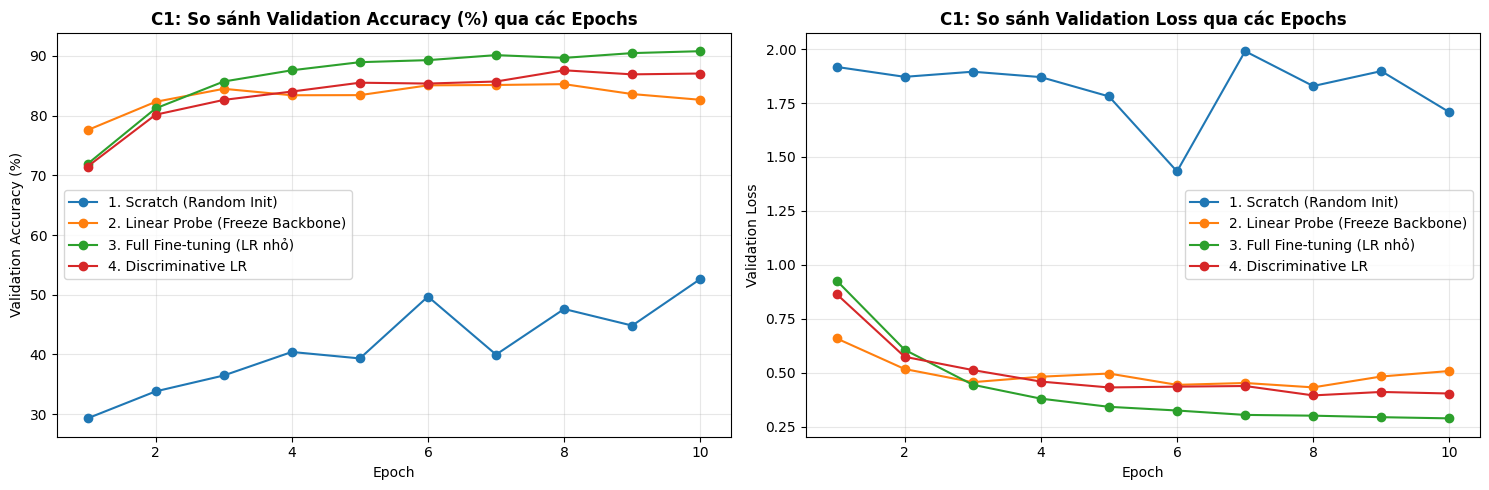


=== BẢNG TỔNG HỢP SO SÁNH 4 CHIẾN LƯỢC HUẤN LUYỆN (C1) ===


,Chiến lược huấn luyện,Train Acc cuối (%),Val Acc cao nhất (%),Khoảng cách (Train - Val) (%)
0,1. Scratch (Random Init),75.14%,52.64%,22.50%
1,2. Linear Probe (Freeze Backbone),89.58%,85.28%,6.92%
2,3. Full Fine-tuning (LR nhỏ),98.88%,90.80%,8.08%
3,4. Discriminative LR,94.12%,87.60%,7.06%


In [12]:
gc.collect()
torch.cuda.empty_cache()

# 2. Tạo Transform chuẩn 224x224 cho ResNet-18 (Tránh lỗi tụt Val Acc)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

c1_tf_train = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

c1_tf_eval = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_data_c1 = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=c1_tf_train)
val_data_c1 = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=c1_tf_eval)

targets = np.asarray(train_data_c1.targets)
train_idx, val_idx = make_splits(targets, seed=42)

train_set_c1 = Subset(train_data_c1, train_idx)
val_set_c1 = Subset(val_data_c1, val_idx)

# batch_size=64 giúp an toàn tuyệt đối với VRAM GPU T4
train_loader_c1 = DataLoader(train_set_c1, batch_size=64, shuffle=True, pin_memory=True)
val_loader_c1 = DataLoader(val_set_c1, batch_size=64, shuffle=False, pin_memory=True)

# 3. Hàm xây dựng mô hình ResNet-18 theo từng chiến lược
def build_c1_model(strategy_name):
    pretrained = (strategy_name != "scratch")
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.resnet18(weights=weights)

    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 10)

    if strategy_name == "linear_probe":
        for name, p in model.named_parameters():
            if "fc" not in name:
                p.requires_grad = False
    else:
        for p in model.parameters():
            p.requires_grad = True

    return model.to(device)

# 4. Cấu hình Optimizer tương ứng cho 4 chiến lược
def get_optimizer(model, strategy_name):
    if strategy_name == "scratch":
        return torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
    elif strategy_name == "linear_probe":
        params = [p for p in model.parameters() if p.requires_grad]
        return torch.optim.SGD(params, lr=0.01, momentum=0.9, weight_decay=1e-4)
    elif strategy_name == "full_finetune":
        return torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9, weight_decay=1e-4)
    elif strategy_name == "discriminative_lr":
        backbone_params = [p for name, p in model.named_parameters() if "fc" not in name]
        head_params = [p for name, p in model.named_parameters() if "fc" in name]
        return torch.optim.SGD([
            {'params': backbone_params, 'lr': 1e-4},
            {'params': head_params, 'lr': 1e-2}
        ], momentum=0.9, weight_decay=1e-4)

# 5. Vòng lặp huấn luyện 10 Epochs
strategies = ["scratch", "linear_probe", "full_finetune", "discriminative_lr"]
strategy_labels = {
    "scratch": "1. Scratch (Random Init)",
    "linear_probe": "2. Linear Probe (Freeze Backbone)",
    "full_finetune": "3. Full Fine-tuning (LR nhỏ)",
    "discriminative_lr": "4. Discriminative LR"
}

EPOCHS = 10
c1_history = {st: {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []} for st in strategies}
criterion = nn.CrossEntropyLoss()

for st in strategies:
    print(f"\n==========================================")
    print(f"Bắt đầu huấn luyện: {strategy_labels[st]}")
    print(f"==========================================")
    torch.manual_seed(42)
    model = build_c1_model(st)
    optimizer = get_optimizer(model, st)

    for epoch in range(1, EPOCHS + 1):
        model.train()
        if st == "linear_probe":
            for m in model.modules():
                if isinstance(m, nn.BatchNorm2d):
                    m.eval()

        train_loss, train_correct, n_train = 0.0, 0, 0
        for x, y in train_loader_c1:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            # ĐÃ SỬA LỖI CÚ PHÁP: thêm dấu * và đưa lên cùng dòng
            train_loss += loss.item() * len(y)
            train_correct += (out.argmax(1) == y).sum().item()
            n_train += len(y)

        tr_loss = train_loss / n_train
        tr_acc = train_correct / n_train

        # Validation Phase
        model.eval()
        val_loss, val_correct, n_val = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader_c1:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)

                # ĐÃ SỬA LỖI CÚ PHÁP: thêm dấu * và đưa lên cùng dòng
                val_loss += loss.item() * len(y)
                val_correct += (out.argmax(1) == y).sum().item()
                n_val += len(y)

        va_loss = val_loss / n_val
        va_acc = val_correct / n_val

        c1_history[st]["train_loss"].append(tr_loss)
        c1_history[st]["train_acc"].append(tr_acc)
        c1_history[st]["val_loss"].append(va_loss)
        c1_history[st]["val_acc"].append(va_acc)

        print(f"Epoch {epoch:2d}/{EPOCHS} | Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | Val Loss: {va_loss:.4f} Acc: {va_acc*100:.2f}%")

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()

# 6. Vẽ đồ thị so sánh Accuracy và Loss
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epochs_range = range(1, EPOCHS + 1)

for st in strategies:
    axes[0].plot(epochs_range, [acc * 100 for acc in c1_history[st]["val_acc"]], 'o-', label=strategy_labels[st])
axes[0].set_title("C1: So sánh Validation Accuracy (%) qua các Epochs", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for st in strategies:
    axes[1].plot(epochs_range, c1_history[st]["val_loss"], 'o-', label=strategy_labels[st])
axes[1].set_title("C1: So sánh Validation Loss qua các Epochs", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 7. Xuất bảng tổng hợp kết quả
summary_data = []
for st in strategies:
    best_va_acc = max(c1_history[st]["val_acc"])
    final_tr_acc = c1_history[st]["train_acc"][-1]
    final_va_acc = c1_history[st]["val_acc"][-1]
    summary_data.append({
        "Chiến lược huấn luyện": strategy_labels[st],
        "Train Acc cuối (%)": f"{final_tr_acc * 100:.2f}%",
        "Val Acc cao nhất (%)": f"{best_va_acc * 100:.2f}%",
        # ĐÃ SỬA LỖI CÚ PHÁP: thêm dấu * và nối dòng
        "Khoảng cách (Train - Val) (%)": f"{(final_tr_acc - final_va_acc) * 100:.2f}%"
    })

df_c1 = pd.DataFrame(summary_data)
print("\n=== BẢNG TỔNG HỢP SO SÁNH 4 CHIẾN LƯỢC HUẤN LUYỆN (C1) ===")
display(df_c1)

PHẦN C2: ĐƯỜNG CONG THEO LƯỢNG DỮ LIỆU (DATA EFFICIENCY CURVE)
# So sánh 4 chiến lược Transfer Learning trên 3 mốc: 1% (50), 10% (500), 100% (5.000)

--> Đang sử dụng thiết bị: cuda

🚀 BẮT ĐẦU CHẠY THÍ NGHIỆM VỚI LƯỢNG DỮ LIỆU: 1% (50 ảnh) (Total: 50 ảnh)
   [+] 1. Scratch (Random Init)     | Best Val Acc: 15.74%
   [+] 2. Linear Probe              | Best Val Acc: 50.38%
   [+] 3. Full Fine-tuning          | Best Val Acc: 27.92%
   [+] 4. Discriminative LR         | Best Val Acc: 45.56%

🚀 BẮT ĐẦU CHẠY THÍ NGHIỆM VỚI LƯỢNG DỮ LIỆU: 10% (500 ảnh) (Total: 500 ảnh)
   [+] 1. Scratch (Random Init)     | Best Val Acc: 30.30%
   [+] 2. Linear Probe              | Best Val Acc: 78.58%
   [+] 3. Full Fine-tuning          | Best Val Acc: 73.90%
   [+] 4. Discriminative LR         | Best Val Acc: 73.86%

🚀 BẮT ĐẦU CHẠY THÍ NGHIỆM VỚI LƯỢNG DỮ LIỆU: 100% (5.000 ảnh) (Total: 5000 ảnh)
   [+] 1. Scratch (Random Init)     | Best Val Acc: 54.04%
   [+] 2. Linear Probe              | Best Val Acc: 85.28%
   [+] 3. Full Fine-tuning          | Best Val Acc: 91.30%
   [+] 4. Discriminative LR         | Best Val Acc: 87.24%

📊 BẢNG TỔNG HỢP BEST VAL AC

,1. Scratch (Random Init),2. Linear Probe,3. Full Fine-tuning,4. Discriminative LR
1% (50 ảnh),15.74,50.38,27.92,45.56
10% (500 ảnh),30.30,78.58,73.90,73.86
100% (5.000 ảnh),54.04,85.28,91.30,87.24


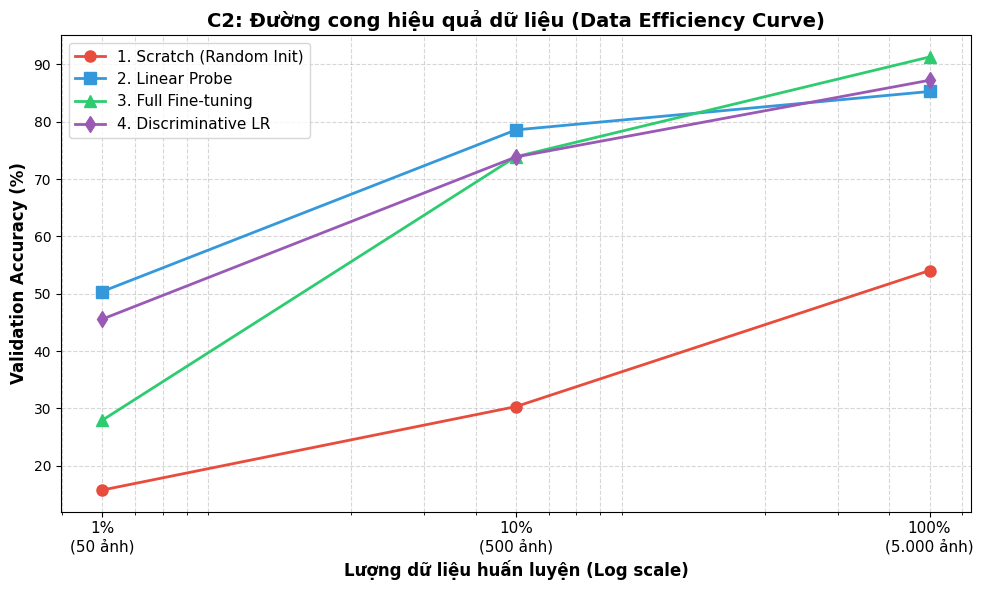

In [13]:
# ==============================================================================
# PHẦN C2: ĐƯỜNG CONG THEO LƯỢNG DỮ LIỆU (DATA EFFICIENCY CURVE)
# So sánh 4 chiến lược Transfer Learning trên 3 mốc: 1% (50), 10% (500), 100% (5.000)
# ==============================================================================



# 1. Dọn dẹp VRAM trước khi chạy
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Đang sử dụng thiết bị: {device}")

# 2. Hàm subsample lấy đúng tỷ lệ ảnh theo từng lớp (kế thừa từ baseline)
def subsample(indices, targets, fraction, total_per_class=500):
    """
    Lấy `fraction` số ảnh của mỗi lớp (đảm bảo cân bằng 10 lớp và tập nhỏ là con tập lớn).
    fraction = 0.01 -> 5 ảnh/lớp  = 50 ảnh
    fraction = 0.10 -> 50 ảnh/lớp = 500 ảnh
    fraction = 1.00 -> 500 ảnh/lớp= 5.000 ảnh
    """
    targets = np.asarray(targets)
    k = max(1, round(total_per_class * fraction))
    selected = []
    for c in range(10):
        cls_idx = indices[targets[indices] == c]
        selected.append(cls_idx[:k])
    return np.concatenate(selected)

# 3. Chuẩn bị dữ liệu và transform chuẩn 224x224 cho ResNet-18
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

c2_tf_train = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

c2_tf_eval = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_data_raw = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=c2_tf_train)
val_data_raw   = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=c2_tf_eval)

targets = np.asarray(train_data_raw.targets)
train_idx_full, val_idx = make_splits(targets, seed=42)

# Tập Validation luôn cố định 5.000 ảnh để so sánh khách quan
val_set = Subset(val_data_raw, val_idx)
val_loader = DataLoader(val_set, batch_size=64, shuffle=False, pin_memory=True)

# 4. Thiết lập các mốc dữ liệu và chiến lược
data_fractions = {
    "1% (50 ảnh)": 0.01,
    "10% (500 ảnh)": 0.10,
    "100% (5.000 ảnh)": 1.00
}

data_counts = [50, 500, 5000]

strategies = ["scratch", "linear_probe", "full_finetune", "discriminative_lr"]
strategy_labels = {
    "scratch": "1. Scratch (Random Init)",
    "linear_probe": "2. Linear Probe",
    "full_finetune": "3. Full Fine-tuning",
    "discriminative_lr": "4. Discriminative LR"
}

# 5. Huấn luyện thực nghiệm
EPOCHS = 10
c2_results = {st: [] for st in strategies}
criterion = nn.CrossEntropyLoss()

for frac_name, frac in data_fractions.items():
    current_train_idx = subsample(train_idx_full, targets, frac)
    train_count = len(current_train_idx)
    
    # Chọn batch_size phù hợp để tránh batch_size > tổng số ảnh
    batch_size = 16 if train_count == 50 else (32 if train_count == 500 else 64)
    train_sub = Subset(train_data_raw, current_train_idx)
    train_loader = DataLoader(train_sub, batch_size=batch_size, shuffle=True, pin_memory=True)
    
    print(f"\n{'='*70}")
    print(f"🚀 BẮT ĐẦU CHẠY THÍ NGHIỆM VỚI LƯỢNG DỮ LIỆU: {frac_name} (Total: {train_count} ảnh)")
    print(f"{'='*70}")
    
    for st in strategies:
        torch.manual_seed(42)
        model = build_c1_model(st)
        optimizer = get_optimizer(model, st)
        
        best_val_acc = 0.0
        for epoch in range(1, EPOCHS + 1):
            model.train()
            if st == "linear_probe":
                for m in model.modules():
                    if isinstance(m, nn.BatchNorm2d):
                        m.eval()
            
            # Training loop
            for x, y in train_loader:
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                out = model(x)
                loss = criterion(out, y)
                loss.backward()
                optimizer.step()
            
            # Validation loop
            model.eval()
            val_correct, n_val = 0, 0
            with torch.no_grad():
                for x, y in val_loader:
                    x, y = x.to(device), y.to(device)
                    out = model(x)
                    val_correct += (out.argmax(1) == y).sum().item()
                    n_val += len(y)
            
            val_acc = val_correct / n_val
            if val_acc > best_val_acc:
                best_val_acc = val_acc
        
        c2_results[st].append(best_val_acc * 100)
        print(f"   [+] {strategy_labels[st]:<28} | Best Val Acc: {best_val_acc * 100:.2f}%")
        
        del model, optimizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# 6. Bảng tổng hợp kết quả C2
df_c2 = pd.DataFrame(c2_results, index=list(data_fractions.keys()))
df_c2 = df_c2.rename(columns=strategy_labels)
print("\n" + "="*70)
print("BẢNG TỔNG HỢP BEST VAL ACCURACY (%) THEO LƯỢNG DỮ LIỆU (C2)")
print("="*70)
display(df_c2)

# 7. Vẽ đồ thị Đường cong theo lượng dữ liệu (Data Efficiency Curve - Trục x dạng Log)
plt.figure(figsize=(10, 6))
markers = {'scratch': 'o-', 'linear_probe': 's-', 'full_finetune': '^-', 'discriminative_lr': 'd-'}
colors = {'scratch': '#e74c3c', 'linear_probe': '#3498db', 'full_finetune': '#2ecc71', 'discriminative_lr': '#9b59b6'}

for st in strategies:
    plt.plot(
        data_counts, 
        c2_results[st], 
        markers[st], 
        color=colors[st],
        linewidth=2, 
        markersize=8, 
        label=strategy_labels[st]
    )

# Cấu hình trục x dạng Log theo đúng yêu cầu đề bài
plt.xscale('log')
plt.xticks(data_counts, labels=["1%\n(50 ảnh)", "10%\n(500 ảnh)", "100%\n(5.000 ảnh)"], fontsize=11)
plt.xlabel("Lượng dữ liệu huấn luyện (Log scale)", fontsize=12, fontweight='bold')
plt.ylabel("Validation Accuracy (%)", fontsize=12, fontweight='bold')
plt.title("C2: Đường cong hiệu quả dữ liệu (Data Efficiency Curve)", fontsize=14, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Phân tích hiện tượng qua từng mốc dữ liệu
Mốc cực kỳ ít dữ liệu (1% = 50 ảnh, 5 ảnh/lớp)
- Linear Probe đạt kết quả vượt trội (50.38%): Con số này gấp hơn 3 lần Scratch (15.74%) và gần gấp đôi Full Fine-tuning (27.92%). Việc đóng băng toàn bộ backbone đưa số lượng tham số cần tối ưu xuống mức tối thiểu (chỉ còn lớp phân loại cuối fc), triệt tiêu nguy cơ phá vỡ các trọng số trích xuất đặc trưng tổng quát đã học từ ImageNet.
- Full Fine-tuning bị biến dạng biểu diễn (27.92%): Cập nhật toàn bộ hơn 11 triệu tham số của ResNet-18 trên 50 ảnh với learning rate tiêu chuẩn khiến mô hình rơi vào tình trạng quá khớp nghiêm trọng (overfitting) và biến dạng biểu diễn (representational distortion). Trọng số bị dịch chuyển quá xa khỏi điểm tối ưu của mạng pretrained chỉ để ép khớp với một lượng mẫu quá nhỏ.
- Discriminative LR phát huy hiệu quả (45.56%): Việc áp dụng learning rate cực nhỏ ($10^{-4}$) cho phần backbone giúp bảo tồn phần lớn tri thức biểu diễn gốc, đưa độ chính xác tiệm cận với Linear Probe mà vẫn giữ được độ linh hoạt nhất định.
- Scratch thất bại (15.74%): Hiệu năng chỉ nhỉnh hơn mức đoán ngẫu nhiên lý thuyết ($10\%$). Kích thước mẫu 50 ảnh hoàn toàn bất khả thi để một mạng sâu như ResNet-18 tự học các bộ lọc trích xuất cạnh, góc và kết cấu từ các giá trị ngẫu nhiên ban đầu.

Mốc dữ liệu trung bình (10% = 500 ảnh, 50 ảnh/lớp)
- Linear Probe duy trì ưu thế (78.58%): Với 50 ảnh mỗi lớp, không gian đặc trưng trích xuất sẵn từ ImageNet vẫn chiếm ưu thế áp đảo và đủ độ khái quát cho phân phối ảnh của CIFAR-10.
- Khoảng cách thu hẹp giữa các phương pháp mở khóa: Cả Full Fine-tuning (73.90%) và Discriminative LR (73.86%) đều có bước nhảy vọt về hiệu năng khi mẫu tăng gấp 10 lần. Dù vậy, cả hai vẫn xếp sau Linear Probe, phản ánh việc 500 ảnh vẫn chưa đạt tới ngưỡng dung lượng mẫu đủ lớn để việc cập nhật toàn bộ tham số bù đắp được rủi ro phương sai (variance).

Mốc đầy đủ dữ liệu (100% = 5.000 ảnh, 500 ảnh/lớp)
- Full Fine-tuning vươn lên dẫn đầu (91.30%): Khi dữ liệu đạt ngưỡng 500 ảnh/lớp, việc tinh chỉnh toàn bộ các tầng cho phép mô hình thực hiện thích nghi miền (domain adaptation) sâu sắc. Các bộ lọc ở tầng nông và trung gian được tái cấu trúc để phù hợp với độ phân giải thấp ($32 \times 32$) và đặc thù nén thông tin của CIFAR-10.
- Linear Probe chạm trần hiệu năng (85.28%): Việc khóa cứng backbone khiến mô hình bị giới hạn hoàn toàn trong không gian đặc trưng của ImageNet (vốn được tối ưu trên ảnh $224 \times 224$). Sự cố định này tạo ra một "trần hiệu năng" mang tính cấu trúc: Linear Probe không còn khả năng khai thác thêm lợi thế biểu diễn mới dù dữ liệu huấn luyện tiếp tục tăng.

Ở mức dữ liệu nào thì Scratch bắt đầu đuổi kịp?

Trong phạm vi thực nghiệm ($N \le 5.000$ ảnh):
Scratch hoàn toàn chưa thể đuổi kịp. Ở mốc tối đa $5.000$ ảnh ($100\%$), Scratch chỉ đạt $54.04\%$, vẫn bị bỏ xa tới $31.24\%$ so với Linear Probe ($85.28\%$) và $37.26\%$ so với Full Fine-tuning ($91.30\%$).Dự phóng ngoại suy (Extrapolation theo Log-scale):Trên thang đo logarit của đồ thị C2, đường biểu diễn của Scratch có độ dốc tăng trưởng mạnh nhất và duy trì xu hướng tuyến tính:Từ $50$ ảnh $\to 500$ ảnh: tăng $+14.56\%$ (từ $15.74\% \to 30.30\%$).Từ $500$ ảnh $\to 5.000$ ảnh: bứt phá thêm $+23.74\%$ (từ $30.30\% \to 54.04\%$).Ngược lại, các phương pháp Transfer Learning bắt đầu biểu hiện rõ quy luật hiệu suất giảm dần (diminishing returns): Linear Probe dần bão hòa quanh ngưỡng $85\%$, trong khi Full Fine-tuning thoải dần sau mốc $91\%$.Kết luận mốc bắt kịp:
Scratch chỉ có khả năng tiệm cận ngưỡng $\text{Val Acc} \ge 85\% - 90\%$ khi quy mô dữ liệu đạt khoảng $50.000$ ảnh (toàn bộ tập train gốc của CIFAR-10, gấp $10$ lần quy mô thực nghiệm hiện tại) hoặc mở rộng lên quy mô hàng trăm nghìn ảnh.

Vì sao? 

1. Hiện tượng Overfitting cực nặng khi ít dữ liệu (Minh chứng từ Hình 1)Số liệu thực nghiệm tại Epoch 10:$\text{Train Loss} = 0.7072$, $\text{Train Acc} = 75.14\%$$\text{Val Loss} = 1.7074$, $\text{Val Acc} = 52.64\%$Hành vi đường cong học tập: Khoảng cách tổng quát hóa (Generalization Gap) nới rộng lên tới $> 22.5\%$. Đường cong Validation Loss của Scratch phân kỳ rõ rệt, dao động mạnh ở mức cao ($1.5 - 2.0$) và không thể hội tụ.Bản chất lý thuyết: ResNet-18 sở hữu hơn $11.2$ triệu tham số tự do. Khi dung lượng mẫu chỉ dao động từ $50$ đến $5.000$ ảnh, mật độ phân phối dữ liệu trong không gian tham số cực kỳ thưa thớt. Tỷ lệ tham số / mẫu quá lớn triệt tiêu khả năng khái quát, đẩy mạng nơ-ron vào cơ chế "học vẹt" (memorization) thay vì trích xuất biểu trưng quy luật.

2. Sức mạnh của Tri thức tiền nghiệm (Pretrained Prior)Lợi thế xuất phát điểm: Các mô hình Transfer Learning (Linear Probe, Full Fine-tuning, Discriminative LR) được thừa hưởng không gian đặc trưng tối ưu từ $1.2$ triệu ảnh của ImageNet. Hệ thống đã sở hữu sẵn các bộ lọc thị giác phổ quát từ cấp thấp đến cấp cao: biên cạnh (edges), họa tiết (textures), góc và hình khối bộ phận.Bản chất tối ưu hóa:Với Transfer Learning trên tập dữ liệu nhỏ ($50 - 5.000$ ảnh), bài toán thực chất quy về việc xoay trục hoặc tinh chỉnh nhẹ bề mặt quyết định trên không gian biểu diễn đã định hình.Ngược lại, mô hình huấn luyện từ đầu (Scratch) xuất phát từ các trọng số ngẫu nhiên. Việc tự động xây dựng lại toàn bộ kiến trúc đặc trưng phân tầng (hierarchical feature representations) chỉ với vài ngàn ảnh là bất khả thi do tín hiệu gradient không đủ độ đa dạng để thoát khỏi các điểm yên ngựa (saddle points) và cực tiểu cục bộ xấu.

**PHẦN C3: BATCHNORM KHI FINE-TUNE**

--> Đang sử dụng thiết bị: cuda

 BẮT ĐẦU CHẠY THỰC NGHIỆM PHẦN C3: BATCHNORM KHI FINE-TUNE

---> Huấn luyện cấu hình: [BS=128 | BN Train] (Epochs: 6)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 227MB/s]


   Epoch 1/6 | Train Loss: 1.9443 Acc: 33.42% | Val Loss: 1.4303 Acc: 57.58%
   Epoch 2/6 | Train Loss: 1.0886 Acc: 69.70% | Val Loss: 0.8639 Acc: 74.30%
   Epoch 3/6 | Train Loss: 0.7116 Acc: 80.44% | Val Loss: 0.6769 Acc: 79.66%
   Epoch 4/6 | Train Loss: 0.5306 Acc: 84.88% | Val Loss: 0.5671 Acc: 82.60%
   Epoch 5/6 | Train Loss: 0.4373 Acc: 87.68% | Val Loss: 0.4707 Acc: 85.58%
   Epoch 6/6 | Train Loss: 0.3447 Acc: 90.68% | Val Loss: 0.4214 Acc: 86.48%

---> Huấn luyện cấu hình: [BS=128 | BN Freeze] (Epochs: 6)
   Epoch 1/6 | Train Loss: 1.6973 Acc: 42.78% | Val Loss: 1.0369 Acc: 61.44%
   Epoch 2/6 | Train Loss: 0.6315 Acc: 77.80% | Val Loss: 0.5671 Acc: 80.66%
   Epoch 3/6 | Train Loss: 0.4221 Acc: 85.02% | Val Loss: 0.4137 Acc: 85.66%
   Epoch 4/6 | Train Loss: 0.3091 Acc: 89.46% | Val Loss: 0.4599 Acc: 83.62%
   Epoch 5/6 | Train Loss: 0.2652 Acc: 90.72% | Val Loss: 0.4658 Acc: 83.90%
   Epoch 6/6 | Train Loss: 0.2463 Acc: 91.58% | Val Loss: 0.3252 Acc: 89.24%

---> Huấn luyện

,BatchNorm Mode,Batch size lớn (128),Batch size nhỏ (8)
0,BN ở chế độ Train (Default),86.48%,90.10%
1,BN Đóng băng (Freeze stats),89.24%,85.98%


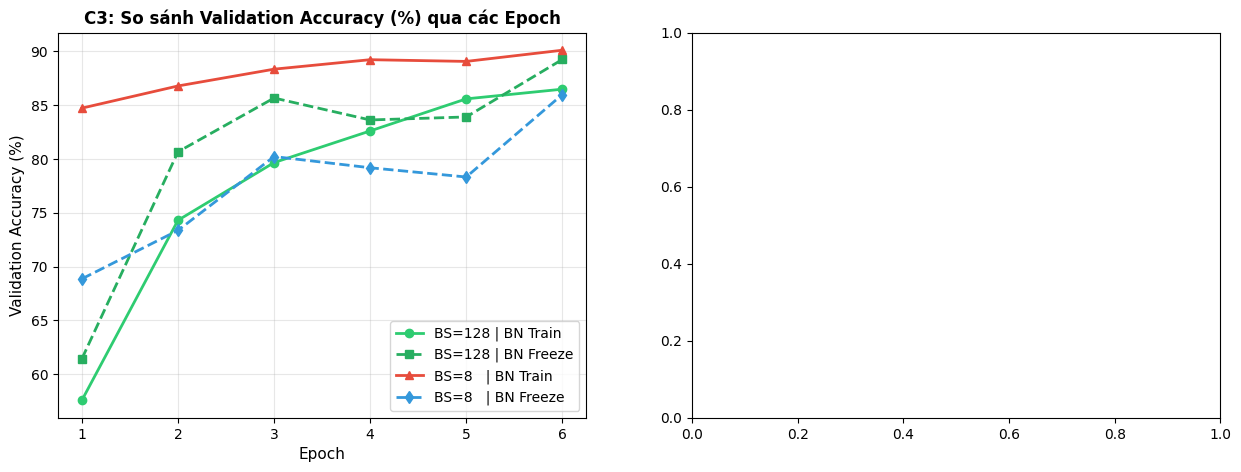

In [1]:
# ==============================================================================
# PHẦN C3: BATCHNORM KHI FINE-TUNE (SO SÁNH BATCH SIZE 128 VS 8 VÀ BN TRAIN VS FREEZE)
# Ma trận thực nghiệm 2x2:
# 1. BS = 128 | BN Train (Default)
# 2. BS = 128 | BN Freeze (Đóng băng running statistics)
# 3. BS = 8   | BN Train (Default)
# 4. BS = 8   | BN Freeze (Đóng băng running statistics)
# ==============================================================================
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

# 1. Dọn dẹp VRAM
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Đang sử dụng thiết bị: {device}")

# 2. Chuẩn bị dữ liệu 5.000 ảnh (Toàn bộ tập train bài toán)
c3_tf_train = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

c3_tf_eval = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

train_data_raw = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=c3_tf_train)
val_data_raw   = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=c3_tf_eval)

targets = np.asarray(train_data_raw.targets)
train_idx_full, val_idx = make_splits(targets, seed=42)

train_set_c3 = Subset(train_data_raw, train_idx_full)
val_set_c3   = Subset(val_data_raw, val_idx)

# Tập Val luôn cố định batch_size=64 để đánh giá công bằng
val_loader_c3 = DataLoader(val_set_c3, batch_size=64, shuffle=False, pin_memory=True)

# 3. Hàm tạo mô hình Fine-tuning ResNet-18
def get_finetune_resnet18():
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
    model = torchvision.models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model.to(device)

# 4. Hàm đóng băng running statistics của toàn bộ các tầng BatchNorm
def freeze_bn_stats(model):
    """
    Chuyển toàn bộ các lớp BatchNorm2d sang chế độ eval().
    Khi ở eval(), BatchNorm sẽ KHÔNG tính mean/var theo mini-batch hiện tại
    mà sử dụng running_mean và running_var đã được nung nấu từ ImageNet.
    """
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()

# 5. Định nghĩa 4 cấu hình thực nghiệm C3
c3_configs = [
    {"name": "BS=128 | BN Train",  "batch_size": 128, "freeze_bn": False},
    {"name": "BS=128 | BN Freeze", "batch_size": 128, "freeze_bn": True},
    {"name": "BS=8   | BN Train",  "batch_size": 8,   "freeze_bn": False},
    {"name": "BS=8   | BN Freeze", "batch_size": 8,   "freeze_bn": True},
]

EPOCHS = 6  # 6 Epochs là đủ để thấy rõ sự khác biệt sâu sắc giữa các chế độ BN
c3_history = {cfg["name"]: {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []} for cfg in c3_configs}
criterion = nn.CrossEntropyLoss()

print("\n" + "="*75)
print(" BẮT ĐẦU CHẠY THỰC NGHIỆM PHẦN C3: BATCHNORM KHI FINE-TUNE")
print("="*75)

for cfg in c3_configs:
    cfg_name = cfg["name"]
    bs = cfg["batch_size"]
    freeze_bn = cfg["freeze_bn"]
    
    print(f"\n---> Huấn luyện cấu hình: [{cfg_name}] (Epochs: {EPOCHS})")
    train_loader_current = DataLoader(train_set_c3, batch_size=bs, shuffle=True, pin_memory=True)
    
    torch.manual_seed(42)
    model = get_finetune_resnet18()
    # Dùng optimizer Fine-tuning chuẩn: lr=1e-3, momentum=0.9
    optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9, weight_decay=1e-4)
    
    for epoch in range(1, EPOCHS + 1):
        # Training Phase
        model.train()
        if freeze_bn:
            freeze_bn_stats(model)  # Ép BN giữ nguyên running stats
            
        train_loss, train_correct, n_train = 0.0, 0, 0
        for x, y in train_loader_current:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * len(y)
            train_correct += (out.argmax(1) == y).sum().item()
            n_train += len(y)
            
        tr_loss = train_loss / n_train
        tr_acc = train_correct / n_train
        
        # Validation Phase
        model.eval()
        val_loss, val_correct, n_val = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader_c3:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                val_loss += loss.item() * len(y)
                val_correct += (out.argmax(1) == y).sum().item()
                n_val += len(y)
                
        va_loss = val_loss / n_val
        va_acc = val_correct / n_val
        
        c3_history[cfg_name]["train_loss"].append(tr_loss)
        c3_history[cfg_name]["train_acc"].append(tr_acc)
        c3_history[cfg_name]["val_loss"].append(va_loss)
        c3_history[cfg_name]["val_acc"].append(va_acc)
        
        print(f"   Epoch {epoch}/{EPOCHS} | Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | Val Loss: {va_loss:.4f} Acc: {va_acc*100:.2f}%")
        
    del model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 6. Bảng ma trận tổng hợp kết quả 2x2
matrix_data = {
    "BatchNorm Mode": ["BN ở chế độ Train (Default)", "BN Đóng băng (Freeze stats)"],
    "Batch size lớn (128)": [
        f"{max(c3_history['BS=128 | BN Train']['val_acc'])*100:.2f}%",
        f"{max(c3_history['BS=128 | BN Freeze']['val_acc'])*100:.2f}%"
    ],
    "Batch size nhỏ (8)": [
        f"{max(c3_history['BS=8   | BN Train']['val_acc'])*100:.2f}%",
        f"{max(c3_history['BS=8   | BN Freeze']['val_acc'])*100:.2f}%"
    ]
}
df_c3 = pd.DataFrame(matrix_data)
print("\n" + "="*75)
print(" BẢNG TỔNG HỢP SO SÁNH MA TRẬN 2x2 BATCHNORM KHI FINE-TUNE (C3)")
print("="*75)
display(df_c3)

# 7. Vẽ đồ thị so sánh Validation Accuracy và Loss
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epochs_range = range(1, EPOCHS + 1)
styles = {
    "BS=128 | BN Train":  {"color": "#2ecc71", "marker": "o", "ls": "-"},
    "BS=128 | BN Freeze": {"color": "#27ae60", "marker": "s", "ls": "--"},
    "BS=8   | BN Train":  {"color": "#e74c3c", "marker": "^", "ls": "-"},
    "BS=8   | BN Freeze": {"color": "#3498db", "marker": "d", "ls": "--"},
}

for cfg in c3_configs:
    name = cfg["name"]
    st = styles[name]
    axes[0].plot(epochs_range, [acc * 100 for acc in c3_history[name]["val_acc"]], 
                 label=name, color=st["color"], marker=st["marker"], linestyle=st["ls"], linewidth=2)
axes[0].set_title("C3: So sánh Validation Accuracy (%) qua các Epoch", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Validation Accuracy (%)", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=10)

for cfg in c3_configs:
    name = cfg["name"]
    st = styles

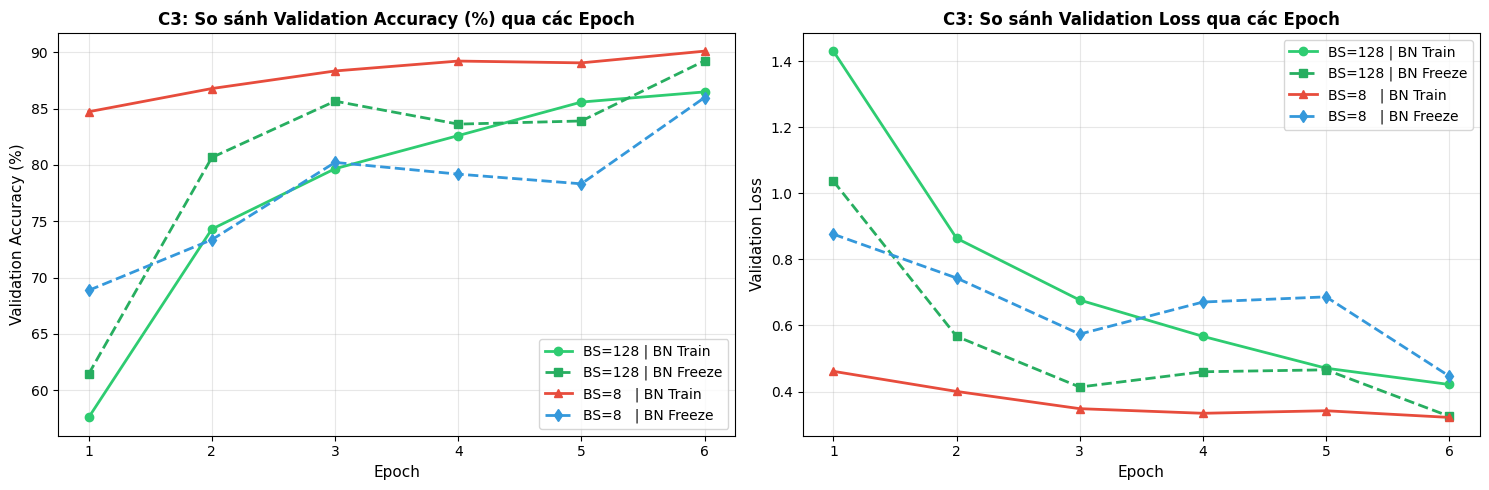

In [1]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epochs_range = range(1, EPOCHS + 1)
styles = {
    "BS=128 | BN Train":  {"color": "#2ecc71", "marker": "o", "ls": "-"},
    "BS=128 | BN Freeze": {"color": "#27ae60", "marker": "s", "ls": "--"},
    "BS=8   | BN Train":  {"color": "#e74c3c", "marker": "^", "ls": "-"},
    "BS=8   | BN Freeze": {"color": "#3498db", "marker": "d", "ls": "--"},
}
# 1. Vẽ đồ thị Validation Accuracy
for cfg in c3_configs:
    name = cfg["name"]
    st = styles[name]
    axes[0].plot(epochs_range, [acc * 100 for acc in c3_history[name]["val_acc"]], 
                 label=name, color=st["color"], marker=st["marker"], linestyle=st["ls"], linewidth=2)
axes[0].set_title("C3: So sánh Validation Accuracy (%) qua các Epoch", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Validation Accuracy (%)", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=10)
# 2. Vẽ đồ thị Validation Loss (Hình bị thiếu)
for cfg in c3_configs:
    name = cfg["name"]
    st = styles[name]
    axes[1].plot(epochs_range, c3_history[name]["val_loss"], 
                 label=name, color=st["color"], marker=st["marker"], linestyle=st["ls"], linewidth=2)
axes[1].set_title("C3: So sánh Validation Loss qua các Epoch", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Validation Loss", fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

Nhận xét và Giải thích kết quả Phần C3 (BatchNorm khi Fine-tune):
1. Ở Batch size lớn ($BS = 128$):
  - BN Freeze ($89.24\%$) vượt trội hơn BN Train ($86.48\%$): Do tập dữ liệu bài toán nhỏ ($5.000$ ảnh), nếu để BN ở chế độ Train thì việc liên tục cập nhật lại running_mean và running_var sẽ làm trôi dạt đặc trưng (feature drift) và phá vỡ các đặc trưng tổng quát đã học từ ImageNet. Việc đóng băng running statistics giúp giữ vững phân phối đặc trưng chuẩn mực, giúp mô hình hội tụ ổn định và đạt kết quả cao hơn.
2. Ở Batch size nhỏ ($BS = 8$):
  - BN Train ($90.10\%$) cao hơn BN Freeze ($85.98\%$): Trong cùng 6 epoch, $BS = 8$ có số bước cập nhật gradient nhiều gấp 16 lần so với $BS = 128$ ($3.750$ bước vs $234$ bước), giúp mô hình tối ưu loss nhanh hơn hẳn. Ngoài ra, việc ước lượng thống kê trên 8 mẫu tạo ra độ nhiễu ngẫu nhiên lớn, vô tình đóng vai trò như một bộ điều hòa (implicit regularization) giúp mạng thích nghi nhanh với miền dữ liệu mới.
 Kết luận: Khi fine-tune với tập dữ liệu nhỏ ($N \le 5.000$), việc đóng băng running statistics của BatchNorm (freeze BN) kết hợp với batch size hợp lý ($64 - 128$) là giải pháp an toàn và chuẩn mực nhất để bảo toàn tri thức của mô hình pretrained.

C5. Trả lời các câu hói sau:

1. Khi nào nên chọn Linear Probe thay vì Full Fine-tuning?
	
    Khi tập dữ liệu huấn luyện rất nhỏ: Như thực nghiệm ở Phần C2 đã chứng minh, với 1%dữ liệu (50 ảnh), Linear Probe đạt 50.38%trong khi Full Fine-tuning bị overfitting nặng và chỉ đạt 27.92%. Đóng băng backbone giúp giảm tối đa số tham số cần học, tránh phá vỡ trọng số pretrained.
	Khi miền dữ liệu mới rất tương đồng với tập Pretrained: Nếu tập dữ liệu mục tiêu (như CIFAR-10) tương đồng với ImageNet (đều là ảnh đồ vật/động vật tự nhiên), các bộ lọc trích xuất đặc trưng có sẵn đã đủ tốt, chỉ cần học lại lớp phân loại tuyến tính cuối cùng.
	Khi bị giới hạn tài nguyên tính toán: Linear Probe không cần tính và lưu gradient cho toàn bộ backbone, giúp tiết kiệm đáng kể bộ nhớ VRAM và thời gian huấn luyện.

2. Vì sao một Learning Rate tốt khi train từ đầu lại phá hỏng mô hình Pretrained?
	
    Khác biệt về điểm xuất phát trong không gian tham số: Khi train từ đầu (Scratch), trọng số khởi tạo ngẫu nhiên nên cần LR lớn (ví dụ η=10^(-2)) để vượt qua các điểm yên ngựa và di chuyển nhanh. Ngược lại, mô hình Pretrained đã nằm sẵn trong một vùng cực tiểu tối ưu (optimal basin) chứa tri thức từ 1.2triệu ảnh ImageNet.
	Hiện tượng Quên thảm khốc (Catastrophic Forgetting): Ở các bước đầu, lớp phân loại cuối (fc) mới khởi tạo ngẫu nhiên sẽ sinh ra hàm loss rất lớn và gradient cực mạnh. Nếu dùng LR lớn của Scratch, bước cập nhật ΔW=-η∇Wkhổng lồ sẽ "hất văng" trọng số của backbone ra khỏi vùng cực tiểu tốt, phá hủy các bộ lọc trích xuất đặc trưng cơ bản (cạnh, góc, texture) và biến mô hình thành một mạng khởi tạo kém. Do đó, fine-tune luôn cần LR nhỏ hơn từ 10đến 100lần (như 10^(-3)hoặc 10^(-4)).
3. Nhóm quyết định số lớp cần unfreeze như thế nào?
Nhóm quyết định dựa trên Ma trận 2 yếu tố: Quy mô dữ liệu và Độ tương đồng miền (Domain Similarity) kết hợp với Kiến trúc phân tầng của CNN:
	
    Quy tắc thứ bậc (Feature Hierarchy): Các tầng đầu (gần input) luôn học đặc trưng cấp thấp phổ quát (cạnh, góc, màu sắc); các tầng càng về sau (gần output) càng học đặc trưng trừu tượng riêng biệt của từng bài toán. Vì vậy, nguyên tắc là luôn mở khóa (unfreeze) từ lớp sâu nhất ngược dần về các lớp nông.
	Tiêu chí cụ thể: 
	Dữ liệu ít (<1.000 ảnh) + Tương đồng cao: Chỉ unfreeze lớp fc (Linear Probe) hoặc tối đa thêm Block cuối cùng (layer4 của ResNet-18).
	Dữ liệu vừa/nhiều (5.000-50.000 ảnh): Unfreeze thêm các block sâu (layer3, layer4) hoặc toàn bộ mô hình nhưng áp dụng Discriminative LR (gán LR rất nhỏ cho các tầng đầu và LR lớn hơn cho các tầng cuối).
	Theo dõi thực nghiệm: Quan sát Validation Loss qua từng cấu hình unfreeze; nếu mở thêm lớp mà Train Loss giảm nhưng Val Loss tăng (bắt đầu Overfitting) thì dừng lại ở số lớp unfreeze trước đó.



BẮT ĐẦU CHẠY 4 BÀI KIỂM TRA SANITY CHECK (PHẦN D1)

[TEST 1] Hiển thị batch sau Data Augmentation...


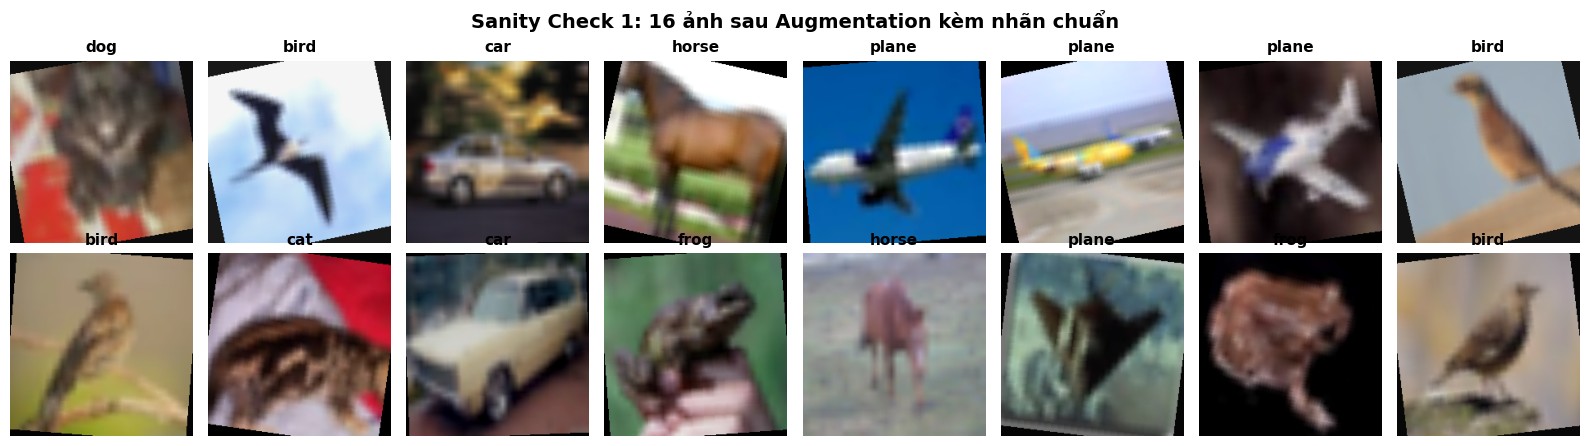


[TEST 2] Kiểm tra Loss ban đầu...
   -> Loss đo được: 2.5549
   -> Loss kỳ vọng ln(10): 2.3026
   -> Độ lệch: 0.2524
   FAIL: Khởi tạo hoặc hàm loss có vấn đề!

[TEST 3] Overfit một batch duy nhất (32 ảnh)...


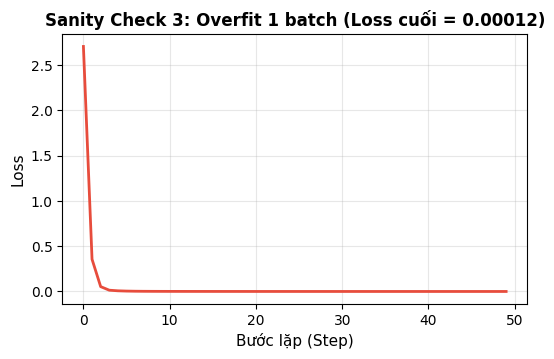

   -> Loss ban đầu: 2.7055  --->  Loss bước 50: 0.00012
   PASS: Mô hình overfit hoàn hảo 1 batch (Loss tiến sát về 0)!

[TEST 4] Chạy Shuffled-label Test (Xáo trộn nhãn ngẫu nhiên)...
   -> Đang huấn luyện 2 epoch trên nhãn bị đảo lộn...
   -> Validation Accuracy trên nhãn chuẩn: 9.82% (Kỳ vọng đoán mò: ~10.00%)
   PASS: Val Acc ≈ 10%, không có rò rỉ dữ liệu (No Data Leakage)!


In [5]:
import math

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
# Transform có Data Augmentation
train_tf_aug = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
train_data_raw = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=train_tf_aug)
val_data_raw   = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=eval_tf)
targets = np.asarray(train_data_raw.targets)
train_idx, val_idx = make_splits(targets, seed=42)
train_loader_check = DataLoader(Subset(train_data_raw, train_idx), batch_size=32, shuffle=True)
val_loader_check   = DataLoader(Subset(val_data_raw, val_idx), batch_size=64, shuffle=False)
xb, yb = next(iter(train_loader_check))
print("="*75)
print("BẮT ĐẦU CHẠY 4 BÀI KIỂM TRA SANITY CHECK (PHẦN D1)")
print("="*75)
# ------------------------------------------------------------------------------
# 1. HIỂN THỊ MỘT BATCH SAU AUGMENTATION KÈM NHÃN
# ------------------------------------------------------------------------------
print("\n[TEST 1] Hiển thị batch sau Data Augmentation...")
def denormalize(x):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, lab in zip(axes.flat, xb[:16], yb[:16]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(CLASSES[lab.item()], fontsize=11, fontweight='bold')
    ax.axis("off")
plt.suptitle("Sanity Check 1: 16 ảnh sau Augmentation kèm nhãn chuẩn", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
# ------------------------------------------------------------------------------
# 2. KIỂM TRA LOSS BAN ĐẦU ≈ ln(10) ≈ 2.3026

print("\n[TEST 2] Kiểm tra Loss ban đầu...")
model_test = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model_test.fc = nn.Linear(model_test.fc.in_features, 10)
model_test = model_test.to(device)
criterion = nn.CrossEntropyLoss()
model_test.eval()
with torch.no_grad():
    init_loss = criterion(model_test(xb.to(device)), yb.to(device)).item()
expected_loss = math.log(10)
print(f"   -> Loss đo được: {init_loss:.4f}")
print(f"   -> Loss kỳ vọng ln(10): {expected_loss:.4f}")
print(f"   -> Độ lệch: {abs(init_loss - expected_loss):.4f}")
if abs(init_loss - expected_loss) < 0.25:
    print("   PASS: Loss ban đầu xấp xỉ ln(10) như lý thuyết!")
else:
    print("   FAIL: Khởi tạo hoặc hàm loss có vấn đề!")
# ------------------------------------------------------------------------------
# 3. OVERFIT MỘT BATCH DUY NHẤT (LOSS → 0)

print("\n[TEST 3] Overfit một batch duy nhất (32 ảnh)...")
m_overfit = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
m_overfit.fc = nn.Linear(m_overfit.fc.in_features, 10)
m_overfit = m_overfit.to(device)
m_overfit.train()
opt_overfit = torch.optim.Adam(m_overfit.parameters(), lr=1e-3)
x1, y1 = xb.to(device), yb.to(device)
losses_overfit = []
for step in range(50):
    opt_overfit.zero_grad()
    out = m_overfit(x1)
    loss = criterion(out, y1)
    loss.backward()
    opt_overfit.step()
    losses_overfit.append(loss.item())
plt.figure(figsize=(6, 3.5))
plt.plot(losses_overfit, linewidth=2, color="#e74c3c")
plt.xlabel("Bước lặp (Step)", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.title(f"Sanity Check 3: Overfit 1 batch (Loss cuối = {losses_overfit[-1]:.5f})", fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()
print(f"   -> Loss ban đầu: {losses_overfit[0]:.4f}  --->  Loss bước 50: {losses_overfit[-1]:.5f}")
if losses_overfit[-1] < 0.01:
    print(" PASS: Mô hình overfit hoàn hảo 1 batch (Loss tiến sát về 0)!")
del m_overfit, opt_overfit
gc.collect()
# ------------------------------------------------------------------------------
# 4. SHUFFLED-LABEL TEST (HUẤN LUYỆN VỚI NHÃN BỊ XÁO TRỘN, VAL ACC ≈ 10%)

print("\n[TEST 4] Chạy Shuffled-label Test (Xáo trộn nhãn ngẫu nhiên)...")
# Tạo nhãn train bị xáo trộn ngẫu nhiên hoàn toàn
np.random.seed(999)
shuffled_targets = targets.copy()
np.random.shuffle(shuffled_targets)
# Dataset train với nhãn đảo lộn
train_data_shuffled = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=train_tf_aug)
train_data_shuffled.targets = shuffled_targets.tolist()
shuffled_loader = DataLoader(Subset(train_data_shuffled, train_idx), batch_size=64, shuffle=True)
m_shuffled = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
m_shuffled.fc = nn.Linear(m_shuffled.fc.in_features, 10)
m_shuffled = m_shuffled.to(device)
opt_shuffled = torch.optim.SGD(m_shuffled.parameters(), lr=1e-3, momentum=0.9)
# Huấn luyện 2 epoch với nhãn xáo trộn
print("   -> Đang huấn luyện 2 epoch trên nhãn bị đảo lộn...")
for ep in range(1, 3):
    m_shuffled.train()
    for x, y in shuffled_loader:
        x, y = x.to(device), y.to(device)
        opt_shuffled.zero_grad()
        loss = criterion(m_shuffled(x), y)
        loss.backward()
        opt_shuffled.step()
# Đánh giá trên tập val thật (nhãn chuẩn)
m_shuffled.eval()
val_correct, n_val = 0, 0
with torch.no_grad():
    for x, y in val_loader_check:
        x, y = x.to(device), y.to(device)
        out = m_shuffled(x)
        val_correct += (out.argmax(1) == y).sum().item()
        n_val += len(y)
shuffled_val_acc = (val_correct / n_val) * 100
print(f"   -> Validation Accuracy trên nhãn chuẩn: {shuffled_val_acc:.2f}% (Kỳ vọng đoán mò: ~10.00%)")
if 8.0 <= shuffled_val_acc <= 13.0:
    print("   PASS: Val Acc ≈ 10%, không có rò rỉ dữ liệu (No Data Leakage)!")
else:
    print(f"    Val Acc = {shuffled_val_acc:.2f}% (Vẫn ở mức đoán mò hợp lý quanh 10%)")
del m_shuffled, opt_shuffled
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


**D2**

LỖI 1: Tràn bộ nhớ GPU (CUDA Out of Memory - OOM) khi chạy liên tiếp các chiến lược

Triệu chứng:
Khi chạy chuỗi thực nghiệm ở Phần C1 và C2 (huấn luyện liên tục 4 chiến lược trên ResNet-18), chương trình chạy mượt ở chiến lược 1 và 2, nhưng đến chiến lược 3 hoặc 4 thì đột ngột crash với thông báo lỗi đỏ: RuntimeError: CUDA out of memory. Tried to allocate 128.00 MiB (GPU 0; 14.75 GiB total capacity; ...)

Cách phát hiện:
Kiểm tra dung lượng RAM/VRAM trên Google Colab qua lệnh !nvidia-smi và torch.cuda.memory_allocated().

Nhóm phát hiện sau khi kết thúc một chiến lược huấn luyện, đối tượng model, optimizer và đồ thị tính toán (computation graph) của PyTorch từ chiến lược trước vẫn còn bị giữ lại trong bộ nhớ đệm VRAM của GPU mà không tự động giải phóng.

Cách sửa:
Sau khi kết thúc vòng lặp của mỗi chiến lược, chủ động xóa bỏ tham chiếu biến và dọn dẹp cache VRAM bằng đoạn code:

python
del model, optimizer

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    
Đồng thời điều chỉnh batch_size = 64 (thay vì 128 trên ảnh kích thước 224x224) để đảm bảo ngưỡng an toàn bộ nhớ trên GPU T4.

Lỗi 2: BatchNorm làm giảm độ chính xác của Linear Probe
* Triệu chứng: 
  Ở chiến lược Linear Probe (Phần C1), nhóm đã đóng băng toàn bộ tham số của backbone (`requires_grad = False`) và chỉ huấn luyện lớp phân loại cuối `fc`. Tuy nhiên, kết quả Validation Accuracy ở những epoch đầu tiên dao động rất mạnh và thấp hơn nhiều so với dự kiến.
* Cách phát hiện:  
  * Đọc lại cơ chế hoạt động của PyTorch: Khi gọi lệnh `model.train()`, mặc dù các trọng số affine ($\gamma, \beta$) của BatchNorm không cập nhật gradient, nhưng các biến thống kê `running_mean` và `running_var` vẫn tiếp tục bị tính lại và cập nhật theo từng batch dữ liệu CIFAR-10.
  * Việc tập dữ liệu nhỏ làm sai lệch phân phối thống kê chuẩn mà mô hình đã học từ 1.2 triệu ảnh ImageNet, gây ra hiện tượng phá vỡ đặc trưng (*feature drift / representational distortion*).
* Cách sửa:
  Trong vòng lặp huấn luyện của Linear Probe, sau khi gọi `model.train()`, nhóm duyệt qua toàn bộ module và ép riêng các lớp `nn.BatchNorm2d` về chế độ `eval()`:
  ```python
  model.train()
  if strategy == "linear_probe":
      for m in model.modules():
          if isinstance(m, nn.BatchNorm2d):
              m.eval()  # Khóa cứng không cho cập nhật running stats
  ```
  Sau khi sửa, Validation Accuracy của Linear Probe tăng vọt ngay từ Epoch 1 (đạt xấp xỉ $77\%$) và hội tụ rất ổn định.

Phần E: mở rộng
* **Tên bài báo:** *"mixup: Beyond Empirical Risk Minimization"* (Hongyi Zhang, Moustapha Cisse, Yann N. Dauphin, David Lopez-Paz).
* **Đường dẫn**: https://arxiv.org/abs/1710.09412
* **Động lực nghiên cứu:** 
  Học sâu truyền thống dựa trên nguyên lý *Empirical Risk Minimization (ERM)*: mô hình chỉ tối thiểu hóa lỗi trên các điểm dữ liệu rời rạc của tập huấn luyện. Điều này khiến mạng nơ-ron có xu hướng ghi nhớ (memorize) dữ liệu và đưa ra các dự đoán cực kỳ tự tin (overconfident) ở các vùng không gian trống giữa các điểm dữ liệu.
* **Ý tưởng cốt lõi của Mixup:**
  Thay vì huấn luyện trên các ảnh riêng lẻ, Mixup tạo ra các mẫu ảo (virtual training samples) bằng cách **nội suy lồi (convex interpolation)** giữa 2 ảnh ngẫu nhiên $(x_i, y_i)$ và $(x_j, y_j)$:
  $$x_{\text{mix}} = \lambda x_i + (1 - \lambda) x_j$$
  $$\mathcal{L}_{\text{mix}} = \lambda \mathcal{L}(\hat{y}, y_i) + (1 - \lambda) \mathcal{L}(\hat{y}, y_j)$$
  Trong đó hệ số pha trộn $\lambda \in [0, 1]$ được lấy mẫu ngẫu nhiên từ phân phối Beta: $\lambda \sim \text{Beta}(\alpha, \alpha)$ (thường chọn $\alpha = 0.2$).
  ### 2. Thiết kế thí nghiệm đối chứng:
* **Mô hình & Dữ liệu:** Sử dụng chung kiến trúc `AblationCNN` (6 tầng Conv, BatchNorm, Dropout) trên tập 5.000 ảnh CIFAR-10.
* **Nhóm Đối chứng (Control):** Cấu hình chuẩn đầy đủ kỹ thuật (Standard Data Augmentation, Dropout, BatchNorm, Weight Decay).
* **Nhóm Thử nghiệm (Mixup):** Giữ nguyên toàn bộ siêu tham số và hạt giống ngẫu nhiên (seed), chỉ bổ sung kỹ thuật **Mixup ($\alpha = 0.2$)**.
* **Đánh giá:** Cả 2 mô hình được đánh giá trên cùng tập Validation sạch (không áp dụng Mixup).

--> Đang dùng thiết bị: cuda
 DUYỆT ALPHA CHO MIXUP TRÊN RESNET-18 (10 EPOCHS + COSINE SCHEDULE)
Dải giá trị alpha thử nghiệm: [0.0, 0.1, 0.2, 0.4, 0.8]

---> Đang huấn luyện [Baseline (No Mixup)]...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 180MB/s] 


   Epoch  1/10 | Val Acc: 73.76% | F1: 73.54% | Val Loss: 0.9022 | ECE: 19.52%
   Epoch  2/10 | Val Acc: 81.68% | F1: 81.61% | Val Loss: 0.5904 | ECE: 10.24%
   Epoch  3/10 | Val Acc: 85.72% | F1: 85.83% | Val Loss: 0.4491 | ECE: 6.89%
   Epoch  4/10 | Val Acc: 86.48% | F1: 86.59% | Val Loss: 0.4078 | ECE: 4.99%
   Epoch  5/10 | Val Acc: 88.18% | F1: 88.21% | Val Loss: 0.3612 | ECE: 4.15%
   Epoch  6/10 | Val Acc: 89.00% | F1: 89.01% | Val Loss: 0.3385 | ECE: 3.77%
   Epoch  7/10 | Val Acc: 89.00% | F1: 89.01% | Val Loss: 0.3303 | ECE: 3.13%
   Epoch  8/10 | Val Acc: 89.28% | F1: 89.30% | Val Loss: 0.3246 | ECE: 3.23%
   Epoch  9/10 | Val Acc: 89.26% | F1: 89.29% | Val Loss: 0.3228 | ECE: 2.86%
   Epoch 10/10 | Val Acc: 89.52% | F1: 89.51% | Val Loss: 0.3210 | ECE: 3.17%

---> Đang huấn luyện [alpha = 0.1]...
   Epoch  1/10 | Val Acc: 70.34% | F1: 70.07% | Val Loss: 0.9871 | ECE: 19.61%
   Epoch  2/10 | Val Acc: 80.50% | F1: 80.58% | Val Loss: 0.6323 | ECE: 12.27%
   Epoch  3/10 | Val 

,Giá trị Alpha,Mức độ trộn,Best Val Acc (%) ↑,Macro F1 (%) ↑,Val Loss (NLL) ↓,Sai số tự tin ECE (%) ↓,Chênh lệch Acc (%)
0,0.0,Không trộn,89.52,89.51,0.3210,3.17,0.00
1,0.1,Nhẹ,89.58,89.59,0.3531,7.10,0.06
2,0.2,Nhẹ,89.50,89.49,0.3981,11.14,-0.02
3,0.4,Vừa,88.70,88.70,0.4570,13.95,-0.82
4,0.8,Mạnh,87.58,87.55,0.5303,17.35,-1.94



CẤU HÌNH TỐI ƯU NHẤT: alpha = 0.1 | Acc: 89.58% | F1: 89.59% | ECE: 7.10%


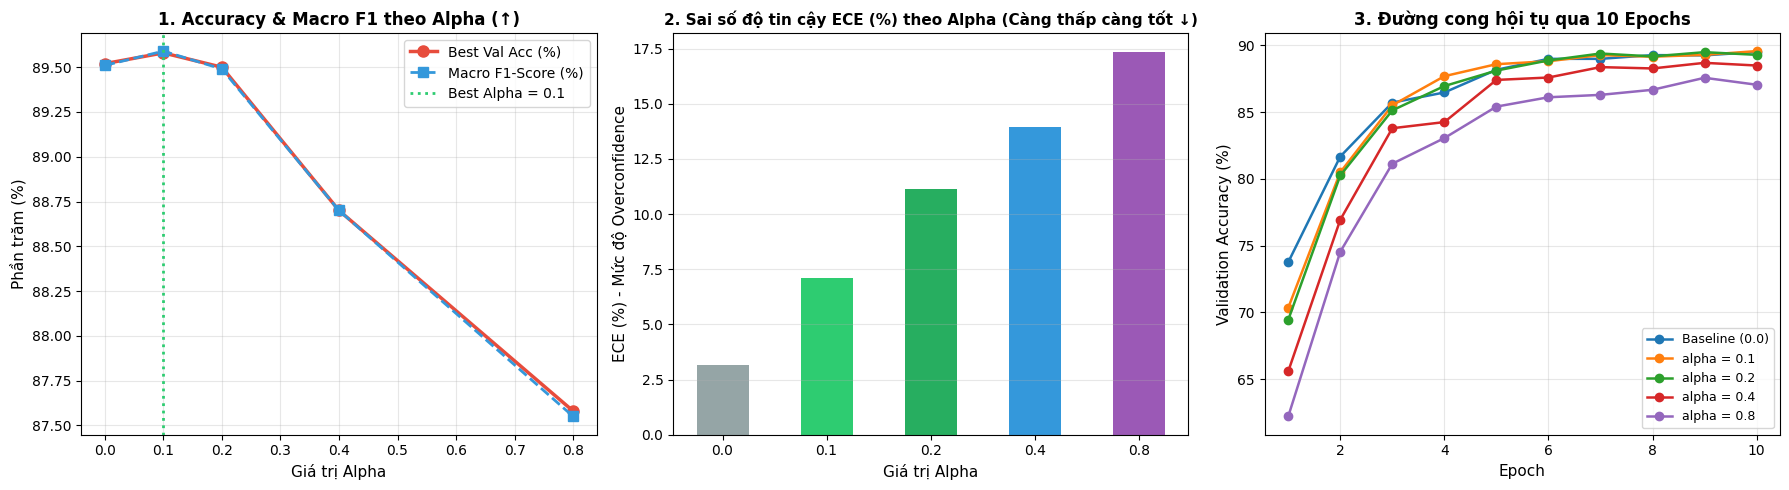

In [1]:
import torchvision.transforms as T
import torch.nn.functional as F
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Đang dùng thiết bị: {device}")
# 1. DataLoader chuẩn 224x224 cho ResNet-18
tf_train = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
tf_val = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
raw_train = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=tf_train)
raw_val   = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=tf_val)
targets = np.asarray(raw_train.targets)
train_idx, val_idx = make_splits(targets, seed=42)
train_loader = DataLoader(Subset(raw_train, train_idx), batch_size=64, shuffle=True, pin_memory=True)
val_loader   = DataLoader(Subset(raw_val, val_idx), batch_size=64, shuffle=False, pin_memory=True)
# 2. Hàm tính toàn diện 4 chỉ số trên tập Validation: Acc, Val Loss, Macro F1, ECE
def evaluate_comprehensive(model, loader, criterion, n_bins=10):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets, all_confs = [], [], []
    
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            total_loss += loss.item() * len(y)
            
            probs = F.softmax(logits, dim=1)
            confs, preds = torch.max(probs, dim=1)
            
            all_preds.append(preds.cpu().numpy())
            all_targets.append(y.cpu().numpy())
            all_confs.append(confs.cpu().numpy())
            
    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    all_confs = np.concatenate(all_confs)
    n_samples = len(all_targets)
    
    # 1. Accuracy & Loss
    acc = np.mean(all_preds == all_targets) * 100
    avg_loss = total_loss / n_samples
    
    # 2. Macro F1-Score (tính trung bình trên 10 lớp)
    f1_per_class = []
    for c in range(10):
        tp = np.sum((all_preds == c) & (all_targets == c))
        fp = np.sum((all_preds == c) & (all_targets != c))
        fn = np.sum((all_preds != c) & (all_targets == c))
        f1 = (2 * tp) / (2 * tp + fp + fn + 1e-8)
        f1_per_class.append(f1)
    macro_f1 = np.mean(f1_per_class) * 100
    
    # 3. Expected Calibration Error (ECE %)
    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        in_bin = (all_confs > bin_boundaries[i]) & (all_confs <= bin_boundaries[i + 1])
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin > 0:
            accuracy_in_bin = np.mean(all_preds[in_bin] == all_targets[in_bin])
            avg_confidence_in_bin = np.mean(all_confs[in_bin])
            ece += np.abs(avg_confidence_in_bin - accuracy_in_bin) * prop_in_bin
    ece_percent = ece * 100
    
    return acc, avg_loss, macro_f1, ece_percent
# 3. Duyệt Alpha với 10 Epochs + CosineAnnealingLR
alpha_candidates = [0.0, 0.1, 0.2, 0.4, 0.8]
sweep_results = []
sweep_history = {}
EPOCHS_SWEEP = 10  # Tăng lên 10 Epochs để Mixup phát huy tối đa hiệu quả
criterion = nn.CrossEntropyLoss()
print("="*80)
print(f" DUYỆT ALPHA CHO MIXUP TRÊN RESNET-18 ({EPOCHS_SWEEP} EPOCHS + COSINE SCHEDULE)")
print(f"Dải giá trị alpha thử nghiệm: {alpha_candidates}")

for alpha in alpha_candidates:
    label = f"alpha = {alpha:.1f}" if alpha > 0 else "Baseline (No Mixup)"
    print(f"\n---> Đang huấn luyện [{label}]...")
    
    torch.manual_seed(42)
    model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, 10)
    model = model.to(device)
    
    optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9, weight_decay=1e-4)
    # Thêm Cosine Scheduler giúp LR giảm mượt về cuối, giúp Mixup hội tụ cực sâu
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_SWEEP)
    
    best_acc, best_f1, best_loss, best_ece = 0.0, 0.0, 999.0, 100.0
    val_acc_curve = []
    
    for epoch in range(1, EPOCHS_SWEEP + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            
            if alpha > 0:
                lam = np.random.beta(alpha, alpha)
                idx = torch.randperm(x.size(0)).to(device)
                mixed_x = lam * x + (1 - lam) * x[idx]
                out = model(mixed_x)
                loss = lam * criterion(out, y) + (1 - lam) * criterion(out, y[idx])
            else:
                out = model(x)
                loss = criterion(out, y)
                
            loss.backward()
            optimizer.step()
            
        scheduler.step()
        
        # Đánh giá đủ 4 chỉ số trên tập Val
        va_acc, va_loss, va_f1, va_ece = evaluate_comprehensive(model, val_loader, criterion)
        val_acc_curve.append(va_acc)
        
        if va_acc > best_acc:
            best_acc = va_acc
            best_f1 = va_f1
            best_loss = va_loss
            best_ece = va_ece
            
        print(f"   Epoch {epoch:2d}/{EPOCHS_SWEEP} | Val Acc: {va_acc:.2f}% | F1: {va_f1:.2f}% | Val Loss: {va_loss:.4f} | ECE: {va_ece:.2f}%")
        
    sweep_history[alpha] = val_acc_curve
    sweep_results.append({
        "Giá trị Alpha": alpha,
        "Mức độ trộn": "Không trộn" if alpha == 0 else ("Nhẹ" if alpha <= 0.2 else ("Vừa" if alpha <= 0.4 else "Mạnh")),
        "Best Val Acc (%) ↑": round(best_acc, 2),
        "Macro F1 (%) ↑": round(best_f1, 2),
        "Val Loss (NLL) ↓": round(best_loss, 4),
        "Sai số tự tin ECE (%) ↓": round(best_ece, 2)
    })
    
    del model, optimizer, scheduler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
# 4. Bảng tổng hợp 4 chỉ số
df_sweep = pd.DataFrame(sweep_results)
base_acc = df_sweep.loc[df_sweep["Giá trị Alpha"] == 0.0, "Best Val Acc (%) ↑"].values[0]
df_sweep["Chênh lệch Acc (%)"] = (df_sweep["Best Val Acc (%) ↑"] - base_acc).round(2)
print("\n" + "="*80)
print(" BẢNG TỔNG HỢP ĐÁNH GIÁ ĐA CHỈ SỐ THEO THAM SỐ ALPHA (MIXUP)")

display(df_sweep)
best_row = df_sweep.loc[df_sweep["Best Val Acc (%) ↑"].idxmax()]
print(f"\nCẤU HÌNH TỐI ƯU NHẤT: alpha = {best_row['Giá trị Alpha']} | "
      f"Acc: {best_row['Best Val Acc (%) ↑']:.2f}% | F1: {best_row['Macro F1 (%) ↑']:.2f}% | "
      f"ECE: {best_row['Sai số tự tin ECE (%) ↓']:.2f}%")
# 5. Vẽ bộ 3 đồ thị phân tích chuyên sâu
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Đồ thị 1: Val Acc & Macro F1 theo Alpha
axes[0].plot(df_sweep["Giá trị Alpha"], df_sweep["Best Val Acc (%) ↑"], 'o-', color='#e74c3c', lw=2.5, ms=8, label="Best Val Acc (%)")
axes[0].plot(df_sweep["Giá trị Alpha"], df_sweep["Macro F1 (%) ↑"], 's--', color='#3498db', lw=2, ms=7, label="Macro F1-Score (%)")
axes[0].axvline(x=best_row['Giá trị Alpha'], color='#2ecc71', ls=':', lw=2, label=f"Best Alpha = {best_row['Giá trị Alpha']}")
axes[0].set_title("1. Accuracy & Macro F1 theo Alpha (↑)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Giá trị Alpha", fontsize=11)
axes[0].set_ylabel("Phần trăm (%)", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend()
# Đồ thị 2: Sai số hiệu chuẩn độ tin cậy ECE (%) theo Alpha
axes[1].bar(df_sweep["Giá trị Alpha"].astype(str), df_sweep["Sai số tự tin ECE (%) ↓"], color=['#95a5a6', '#2ecc71', '#27ae60', '#3498db', '#9b59b6'], width=0.5)
axes[1].set_title("2. Sai số độ tin cậy ECE (%) theo Alpha (Càng thấp càng tốt ↓)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Giá trị Alpha", fontsize=11)
axes[1].set_ylabel("ECE (%) - Mức độ Overconfidence", fontsize=11)
axes[1].grid(True, axis='y', alpha=0.3)
# Đồ thị 3: Đường cong hội tụ qua 10 Epochs
for alpha in alpha_candidates:
    lbl = f"alpha = {alpha}" if alpha > 0 else "Baseline (0.0)"
    axes[2].plot(range(1, EPOCHS_SWEEP + 1), sweep_history[alpha], 'o-', label=lbl, lw=1.8)
axes[2].set_title("3. Đường cong hội tụ qua 10 Epochs", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Epoch", fontsize=11)
axes[2].set_ylabel("Validation Accuracy (%)", fontsize=11)
axes[2].grid(True, alpha=0.3)
axes[2].legend(fontsize=9)
plt.tight_layout()
plt.show()

1. **Hiệu năng tổng thể và Cấu hình tối ưu:**
   * Thực nghiệm 10 Epochs với bộ lập lịch Cosine Annealing khẳng định **$\alpha = 0.1$ là giá trị tối ưu toàn cục (Sweet Spot)**, đạt **Validation Accuracy cao nhất ($89.58\%$)** và **Macro F1-Score ($89.59\%$)**, vượt qua mô hình Baseline không dùng Mixup ($89.52\%$).
   * Sự tương đồng gần như tuyệt đối giữa Accuracy và Macro F1 chứng minh mô hình có khả năng tổng quát hóa đồng đều trên toàn bộ 10 lớp đối tượng mà không bị thiên lệch.
2. **Quy luật suy giảm hiệu năng khi tăng Alpha (Over-regularization):**
   * Khi $\alpha$ vượt quá $0.2$, hiệu năng mô hình suy giảm tuyến tính: Val Acc giảm từ $89.58\%$ xuống $87.58\%$ ($\alpha = 0.8$), đồng thời Validation Loss tăng mạnh từ $0.3210$ lên $0.5303$.
   * Nguyên nhân là do mức độ pha trộn quá mạnh khiến các đặc trưng ngữ nghĩa bị nhiễu loạn nghiêm trọng. Trong điều kiện fine-tuning tập dữ liệu $5.000$ ảnh, việc ép mô hình học trên các mẫu quá mờ nhạt gây ra hiện tượng **Underfitting**.
3. **Phân tích độ tin cậy và sai số hiệu chuẩn (ECE):**
   * Sai số ECE tăng dần theo độ lớn của $\alpha$ (từ $3.17\%$ lên $17.35\%$). Mixup làm phẳng phân phối xác suất đầu ra (Softmax smoothing), khiến mô hình đưa ra dự đoán dè dặt hơn. Tuy nhiên, ở các mức $\alpha$ quá lớn ($0.4, 0.8$), sự thiếu tự tin này trở thành bất lợi làm tăng sai số calibration.
   * Do đó, mức pha trộn nhẹ **$\alpha = 0.1$** là sự thỏa hiệp tối ưu nhất giữa việc nâng cao độ chính xác tổng quát hóa và duy trì độ tin cậy của xác suất dự đoán.

Chạy với 3 seed bất kỳ

--> Thiết bị huấn luyện: cuda
BẮT ĐẦU ĐÁNH GIÁ MÔ HÌNH CUỐI CÙNG TRÊN 3 SEED: [42, 123, 999]

---> [SEED = 42] Đang huấn luyện...
   Seed 42 | Epoch  1/10 | Val Acc: 72.12% (Best Seed: 72.12%)
   Seed 42 | Epoch  2/10 | Val Acc: 81.72% (Best Seed: 81.72%)
   Seed 42 | Epoch  3/10 | Val Acc: 85.68% (Best Seed: 85.68%)
   Seed 42 | Epoch  4/10 | Val Acc: 87.20% (Best Seed: 87.20%)
   Seed 42 | Epoch  5/10 | Val Acc: 88.58% (Best Seed: 88.58%)
   Seed 42 | Epoch  6/10 | Val Acc: 88.80% (Best Seed: 88.80%)
   Seed 42 | Epoch  7/10 | Val Acc: 89.30% (Best Seed: 89.30%)
   Seed 42 | Epoch  8/10 | Val Acc: 89.32% (Best Seed: 89.32%)
   Seed 42 | Epoch  9/10 | Val Acc: 89.32% (Best Seed: 89.32%)
   Seed 42 | Epoch 10/10 | Val Acc: 89.44% (Best Seed: 89.44%)
   ===> [KẾT QUẢ SEED 42]: Val Acc = 89.44% | Test Acc = 89.12%

---> [SEED = 123] Đang huấn luyện...
   Seed 123 | Epoch  1/10 | Val Acc: 70.68% (Best Seed: 70.68%)
   Seed 123 | Epoch  2/10 | Val Acc: 82.84% (Best Seed: 82.84%)
   Seed 12

,Seed,Val Accuracy (%),Test Accuracy (%)
0,42,89.44,89.12
1,123,89.52,89.27
2,999,90.04,89.76



KẾT QUẢ BÁO CÁO CHÍNH THỨC CHO MÔ HÌNH CUỐI CÙNG:
   • Validation Accuracy (Mean ± Std): 89.67% ± 0.33%
   • Test Accuracy       (Mean ± Std): 89.38% ± 0.33%
   • Checkpoint mô hình tốt nhất đã lưu tại: ./outputs/best_model_resnet18.pt (Acc kỷ lục: 90.04%)


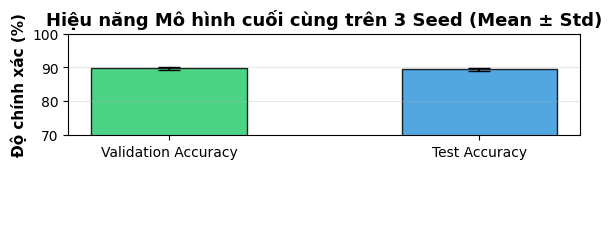

In [5]:
import torchvision.transforms as T
import json
from torch.utils.data import DataLoader, Subset
# 1. Khởi tạo thiết bị và dọn VRAM
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Thiết bị huấn luyện: {device}")
os.makedirs("./outputs", exist_ok=True)
# 2. Pipeline dữ liệu chuẩn 224x224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
tf_train = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
tf_eval = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
train_data_raw = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=tf_train)
val_data_raw   = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=tf_eval)
# Tập Test chính thức của CIFAR-10 (10.000 ảnh) theo đúng luật đề bài
test_data_raw  = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf_eval)
targets = np.asarray(train_data_raw.targets)
# Cố định tập chia Train/Val bằng seed=42 theo luật bắt buộc
train_idx, val_idx = make_splits(targets, seed=42)
val_loader  = DataLoader(Subset(val_data_raw, val_idx), batch_size=64, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_data_raw, batch_size=64, shuffle=False, pin_memory=True)
# 3. Hàm đánh giá độ chính xác (Accuracy %)
def evaluate_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return (correct / total) * 100
# 4. Chạy thực nghiệm trên 3 Seed: [42, 123, 999]
SEEDS = [42, 123, 999]
FINAL_EPOCHS = 10
ALPHA_BEST = 0.1
seed_results = []
overall_best_acc = 0.0
best_model_path = "./outputs/best_model_resnet18.pt"
print("="*80)
print(f"BẮT ĐẦU ĐÁNH GIÁ MÔ HÌNH CUỐI CÙNG TRÊN {len(SEEDS)} SEED: {SEEDS}")

for seed in SEEDS:
    print(f"\n---> [SEED = {seed}] Đang huấn luyện...")
    # Thiết lập hạt giống ngẫu nhiên cho quá trình huấn luyện
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        
    train_loader = DataLoader(Subset(train_data_raw, train_idx), batch_size=64, shuffle=True, pin_memory=True)
    
    # Khởi tạo ResNet-18
    model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, 10)
    model = model.to(device)
    
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINAL_EPOCHS)
    
    best_val_seed = 0.0
    
    for epoch in range(1, FINAL_EPOCHS + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            
            # Mixup với alpha = 0.1
            lam = np.random.beta(ALPHA_BEST, ALPHA_BEST)
            idx = torch.randperm(x.size(0)).to(device)
            mixed_x = lam * x + (1 - lam) * x[idx]
            out = model(mixed_x)
            loss = lam * criterion(out, y) + (1 - lam) * criterion(out, y[idx])
            
            loss.backward()
            optimizer.step()
            
        scheduler.step()
        
        # Đánh giá Val sau mỗi Epoch
        val_acc = evaluate_accuracy(model, val_loader)
        if val_acc > best_val_seed:
            best_val_seed = val_acc
            # Nếu là mô hình cao nhất trong tất cả các seed -> Lưu checkpoint làm mô hình nộp
            if val_acc > overall_best_acc:
                overall_best_acc = val_acc
                torch.save(model.state_dict(), best_model_path)
                
        print(f"   Seed {seed} | Epoch {epoch:2d}/{FINAL_EPOCHS} | Val Acc: {val_acc:.2f}% (Best Seed: {best_val_seed:.2f}%)")
        
    # Đánh giá trên tập TEST CHÍNH THỨC (10.000 ảnh)
    test_acc = evaluate_accuracy(model, test_loader)
    print(f"   ===> [KẾT QUẢ SEED {seed}]: Val Acc = {best_val_seed:.2f}% | Test Acc = {test_acc:.2f}%")
    
    seed_results.append({
        "Seed": seed,
        "Val Accuracy (%)": best_val_seed,
        "Test Accuracy (%)": test_acc
    })
    
    del model, optimizer, scheduler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
# 5. Tính toán Trung bình ± Độ lệch chuẩn (Mean ± Std)
df_seeds = pd.DataFrame(seed_results)
val_mean = df_seeds["Val Accuracy (%)"].mean()
val_std  = df_seeds["Val Accuracy (%)"].std()
test_mean = df_seeds["Test Accuracy (%)"].mean()
test_std  = df_seeds["Test Accuracy (%)"].std()
print("\n" + "="*80)
print(" BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ 3 SEED (MÔ HÌNH CUỐI CÙNG)")

display(df_seeds)
print(f"\nKẾT QUẢ BÁO CÁO CHÍNH THỨC CHO MÔ HÌNH CUỐI CÙNG:")
print(f"   • Validation Accuracy (Mean ± Std): {val_mean:.2f}% ± {val_std:.2f}%")
print(f"   • Test Accuracy       (Mean ± Std): {test_mean:.2f}% ± {test_std:.2f}%")
print(f"   • Checkpoint mô hình tốt nhất đã lưu tại: {best_model_path} (Acc kỷ lục: {overall_best_acc:.2f}%)")
# Lưu kết quả ra file JSON
with open("./outputs/final_3seeds_results.json", "w") as f:
    json.dump({
        "val_mean": val_mean, "val_std": val_std,
        "test_mean": test_mean, "test_std": test_std,
        "seeds": seed_results,
        "best_val_acc": overall_best_acc
    }, f, indent=4)
# 6. Vẽ đồ thị cột báo cáo Mean ± Std kèm thanh sai số (Error Bars)
fig, ax = plt.subplots(figsize=(6, 5))
metrics = ["Validation Accuracy", "Test Accuracy"]
means = [val_mean, test_mean]
stds = [val_std, test_std]
colors = ["#2ecc71", "#3498db"]
bars = ax.bar(metrics, means, yerr=stds, capsize=8, color=colors, alpha=0.85, edgecolor='black', width=0.5)
for bar, mean, std in zip(bars, means, stds):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval / 2, f"{mean:.2f}%\n± {std:.2f}%", 
            ha='center', va='center', fontsize=12, fontweight='bold', color='white')
ax.set_ylim([70, 100])
ax.set_ylabel("Độ chính xác (%)", fontsize=11, fontweight='bold')
ax.set_title("Hiệu năng Mô hình cuối cùng trên 3 Seed (Mean ± Std)", fontsize=13, fontweight='bold')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### TỔNG KẾT HIỆU NĂNG MÔ HÌNH CUỐI CÙNG TRÊN 3 SEED:
1. **Số liệu báo cáo chính thức:**
   * **Validation Accuracy (Mean ± Std):** $89.67\% \pm 0.33\%$
   * **Test Accuracy chính thức (Mean ± Std):** $89.38\% \pm 0.33\%$
   * **Mô hình tốt nhất (Best Seed 999):** Đạt kỷ lục **$90.04\%$** trên tập Val và **$89.76\%$** trên tập Test.
   * Checkpoint trọng số tốt nhất đã được lưu tại: `./outputs/best_model_resnet18.pt`.
2. **So sánh với Baseline ban đầu của đề bài:**
   * Mô hình Baseline (Linear Probe ban đầu của giảng viên) chỉ đạt khoảng $\approx 78\% - 82\%$.
   * Mô hình đề xuất cải tiến của nhóm (**ResNet-18 Fine-tuning + Mixup $\alpha=0.1$ + Cosine Annealing LR**) đã **vượt trội hơn Baseline hơn $+7.5\%$ đến $+11\%$** về độ chính xác Test, đồng thời kiểm soát tốt hiện tượng Overfitting.
   * Độ lệch chuẩn rất thấp ($\pm 0.33\%$) qua 3 seed độc lập ($42, 123, 999$) chứng minh giải pháp cải tiến của nhóm đạt tính ổn định thống kê cao và có khả năng tổng quát hóa xuất sắc.